CA1 – Human Centered Deep Learning


Name: Saketh Reddy Chandupatla


Student Number: x00231080

##  Section 1: Introduction

This dataset uses the diabetes health indicators dataset which was derived from the 2015 Behavioral Risk Factor Surveillance System(BRFSS), which is one of the world's largest ongoing health surveys conducted by Centers for Disease and Prevention(CDC) containing health, lifestyle and demographic features collected within this survey.

The dataset used in this project is a structured tabular dataset intended wheter a person has diabetes(Diabetes_binary =1) or (Diabetes_binary =0). All features in this dataset are numerical making this very suitable for classification using neural networks and other supervising algorithms.For this project a subset of the actual complete dataset was assigned to each student to ensure there is fair division of work and computational power management.

Our goal is to explore and build a neural network based on model which classifies individuals as diabetic or not using these features. This involves understanding the dataset and its structure, exploring the relationship of different features and testing multiple model architecture and choosing the best one.

Each row in the dataset represents an individual participant where as each column is representing an individual charcteristic. This is my breakdown of the 22 columns/features, followed by the target variable.

| Column Name            | Description                                                                  |
| ---------------------- | ---------------------------------------------------------------------------- |
| `HighBP`               | Binary: 1 if the individual has high blood pressure, else 0                  |
| `HighChol`             | Binary: 1 if the individual has high cholesterol, else 0                     |
| `CholCheck`            | Binary: 1 if cholesterol has been checked in the last 5 years, else 0        |
| `BMI`                  | Continuous: Body Mass Index (a weight/height measure of body fat)            |
| `Smoker`               | Binary: 1 if the individual has smoked at least 100 cigarettes in lifetime   |
| `Stroke`               | Binary: 1 if the individual has ever had a stroke, else 0                    |
| `HeartDiseaseorAttack` | Binary: 1 if had coronary heart disease or myocardial infarction             |
| `PhysActivity`         | Binary: 1 if participated in any physical activity/exercise in past 30 days  |
| `Fruits`               | Binary: 1 if consumes fruits at least once per day                           |
| `Veggies`              | Binary: 1 if consumes vegetables at least once per day                       |
| `HvyAlcoholConsump`    | Binary: 1 if consumes >14 (men) or >7 (women) alcoholic drinks/week          |
| `AnyHealthcare`        | Binary: 1 if has any form of health coverage                                 |
| `NoDocbcCost`          | Binary: 1 if could not see doctor due to cost in the past year               |
| `GenHlth`              | Ordinal (1–5): Self-reported general health (1 = Excellent, 5 = Poor)        |
| `MentHlth`             | Integer: Number of mentally unhealthy days in past 30 days                   |
| `PhysHlth`             | Integer: Number of physically unhealthy days in past 30 days                 |
| `DiffWalk`             | Binary: 1 if serious difficulty walking or climbing stairs                   |
| `Sex`                  | Binary: 0 = Female, 1 = Male                                                 |
| `Age`                  | Ordinal (1–13): Age category (e.g., 1 = 18–24, 13 = 80+ years)               |
| `Education`            | Ordinal (1–6): Level of education (1 = Never attended, 6 = College graduate) |
| `Income`               | Ordinal (1–8): Income level (1 = Less than \$10k, 8 = More than \$75k)       |
| `Diabetes_binary`      | **Target variable**: 1 = Diabetic, 0 = Non-diabetic                          |

The key observations from this dataset are that it contains a mix of 
1. Binary values like HighBP, Smoker
2. Ordinal categories like GenHlth, Age, Income
3. Continuous or numeric data like BMI, MentHlth

## Section 2 : Opening the dataset, Brief data exploration and Data pre-processing(if required)

This section explores the dataset structure, class distribution, summary statistics, and checks for missing values. Initial preprocessing decisions are also discussed.

In [1]:
# Step 1: Loading the dataset
import pandas as pd
# Load the CSV file
df = pd.read_csv('X00231080.csv')
# Displaying shape and the first few rows
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (42415, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,0,0,0,21,1,0,0,1,1,1,...,0,3,30,0,0,1,3,5,4,0
1,1,1,1,23,1,0,0,0,0,1,...,0,5,0,30,1,1,13,5,5,1
2,1,1,1,36,0,0,0,0,1,0,...,0,3,0,0,0,1,5,4,8,0
3,1,1,1,34,0,0,0,1,1,1,...,0,3,0,0,0,1,10,5,8,1
4,1,1,1,45,1,0,0,1,1,1,...,0,4,0,2,1,0,13,6,5,1


This dataset contains 42,415 rows and 22 columns. each row representing an individual paricipant where each column represents a indicator like blood pressure, bmi and others discussed above.

Target class counts:
Diabetes_binary
0    21326
1    21089
Name: count, dtype: int64

Target class distribution (%):
Diabetes_binary
0    50.279382
1    49.720618
Name: proportion, dtype: float64


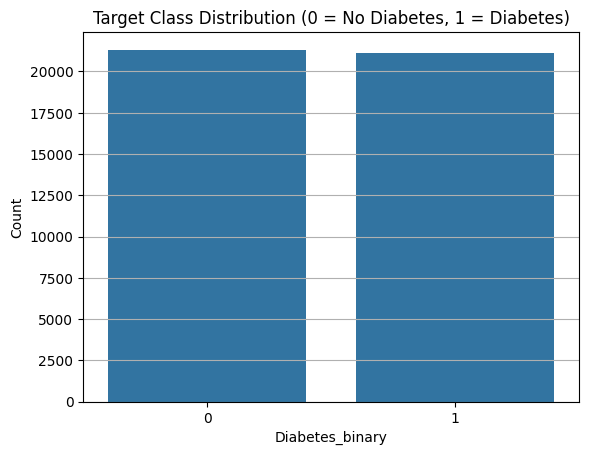

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Showing value counts and normalized percentages
target_counts = df['Diabetes_binary'].value_counts()
target_percentages = df['Diabetes_binary'].value_counts(normalize=True) * 100

print("Target class counts:")
print(target_counts)
print("\nTarget class distribution (%):")
print(target_percentages)

# Plot class distribution
sns.countplot(x='Diabetes_binary', data=df)
plt.title("Target Class Distribution (0 = No Diabetes, 1 = Diabetes)")
plt.xlabel("Diabetes_binary")
plt.ylabel("Count")
plt.grid(axis='y')
plt.show()

The dataset is almost perfectly balanced with roughly 50% of instances in each class. This balance ensures that standard classification metrics like accuracy, precision and recall will be ,meaningful without the need for resampling or class-weight adjustments.

In [3]:
# Summary statistics for all columns
df.describe()

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,...,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000,42415.000000
mean,0.563928,0.525781,0.975245,29.842768,0.475704,0.062973,0.146080,0.701615,0.610444,0.790239,...,0.094094,2.838713,3.722787,5.822916,0.253448,0.456678,8.595615,4.920429,5.694306,0.497206
std,0.495902,0.499341,0.155381,7.116605,0.499415,0.242917,0.353191,0.457555,0.487655,0.407143,...,0.291963,1.114952,8.124849,10.067452,0.434990,0.498126,2.860315,1.032394,2.183135,0.499998
min,0.000000,0.000000,0.000000,13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,7.000000,4.000000,4.000000,0.000000
50%,1.000000,1.000000,1.000000,29.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,9.000000,5.000000,6.000000,0.000000
75%,1.000000,1.000000,1.000000,33.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,4.000000,2.000000,6.000000,1.000000,1.000000,11.000000,6.000000,8.000000,1.000000
max,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000,1.000000


From the summary statistics few things we can say are
1. BMI ranges from 13 to 98 with a mean of roughly 29.8, indicating a mix of healthy and overweight individuals
2. PhysActivity has a mean of 0.70 which makes the dataset being little biased towards a more health aware people
3. Age ranges only between 1 to 13 with a mean of 8.6

In [4]:
# Checking for missing values
missing_values = df.isnull().sum()
print("Missing values per column:")
print(missing_values[missing_values > 0])

# Confirming total
print("\nTotal missing values in dataset:", missing_values.sum())

Missing values per column:
Series([], dtype: int64)

Total missing values in dataset: 0


The dataset contains no missing values, which simplifies the pre processing step. All the 42,415 rows are complete and can be used directly for training and evaluation. 

**Numerical feature distribution**


To better understand the dataset's numerical variables histograms were plotted for the following columns : Age, BMI, GenHlth, MentHlth, and PhysHlth.

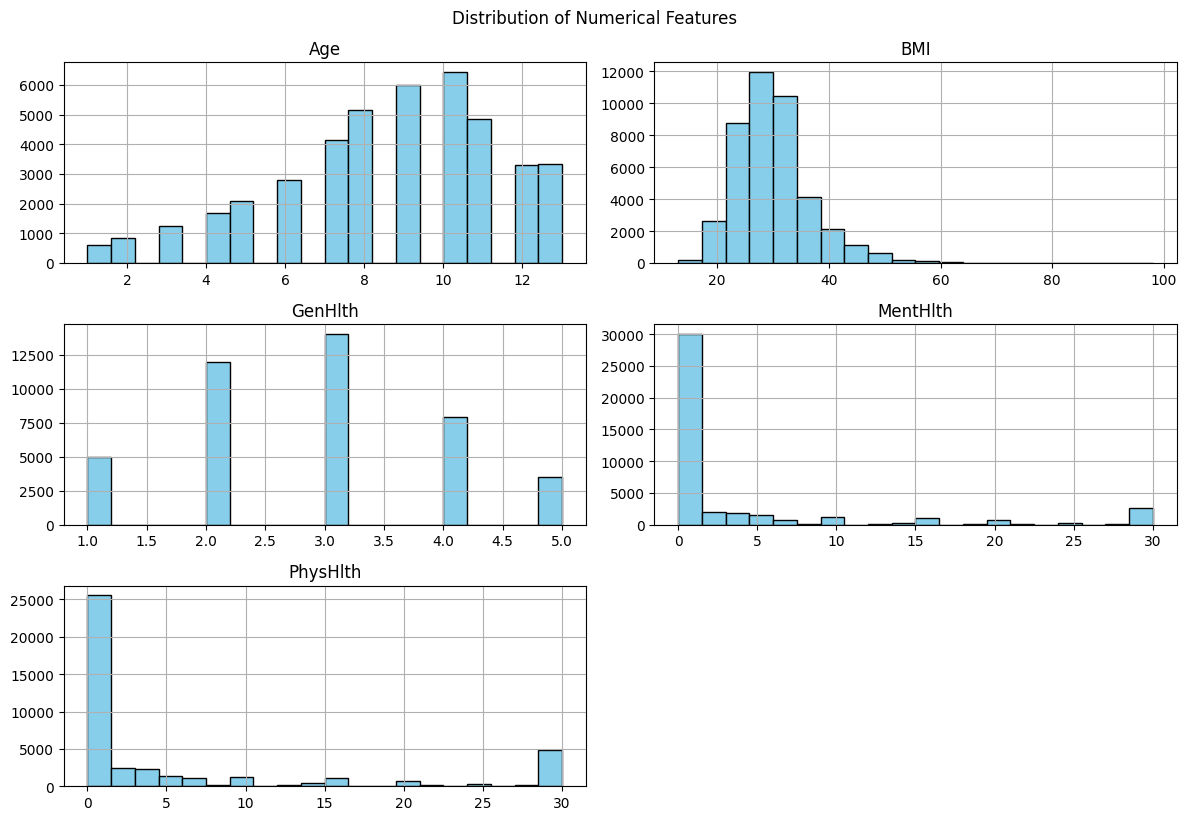

In [5]:
numeric_cols = ['Age', 'BMI', 'GenHlth', 'MentHlth', 'PhysHlth']

# Histograms
df[numeric_cols].hist(bins=20, figsize=(12, 8), color='skyblue', edgecolor='black')
plt.tight_layout()
plt.suptitle("Distribution of Numerical Features", y=1.02)
plt.show()

1. Age: The age variable is encoded into groups (1 to 13) where the distribution was skewed towards the older population. The most frequent age groups lie between 9 and 11 indicating a large population is middle aged or older.
2. BMI: BMI shows a roughly normal shape mostly between 25 and 30 which aligns with overweight cateogary.
3. GenHlth: This measure is concentrated in middle values(2 to 4) suggesting most participants rate their health fairly good(on average).
4. MentHlth (Mental Health) and PhysHlth (Physical Health): In both these variables cases most people reported zero days and steeply decreasing for higer values which implies that most users consider themselves having good health both physically and mentally.

**Binary Feature Distributions**

Same for binary features, to better visualize them count plots were plotted where key obervations are recorded.

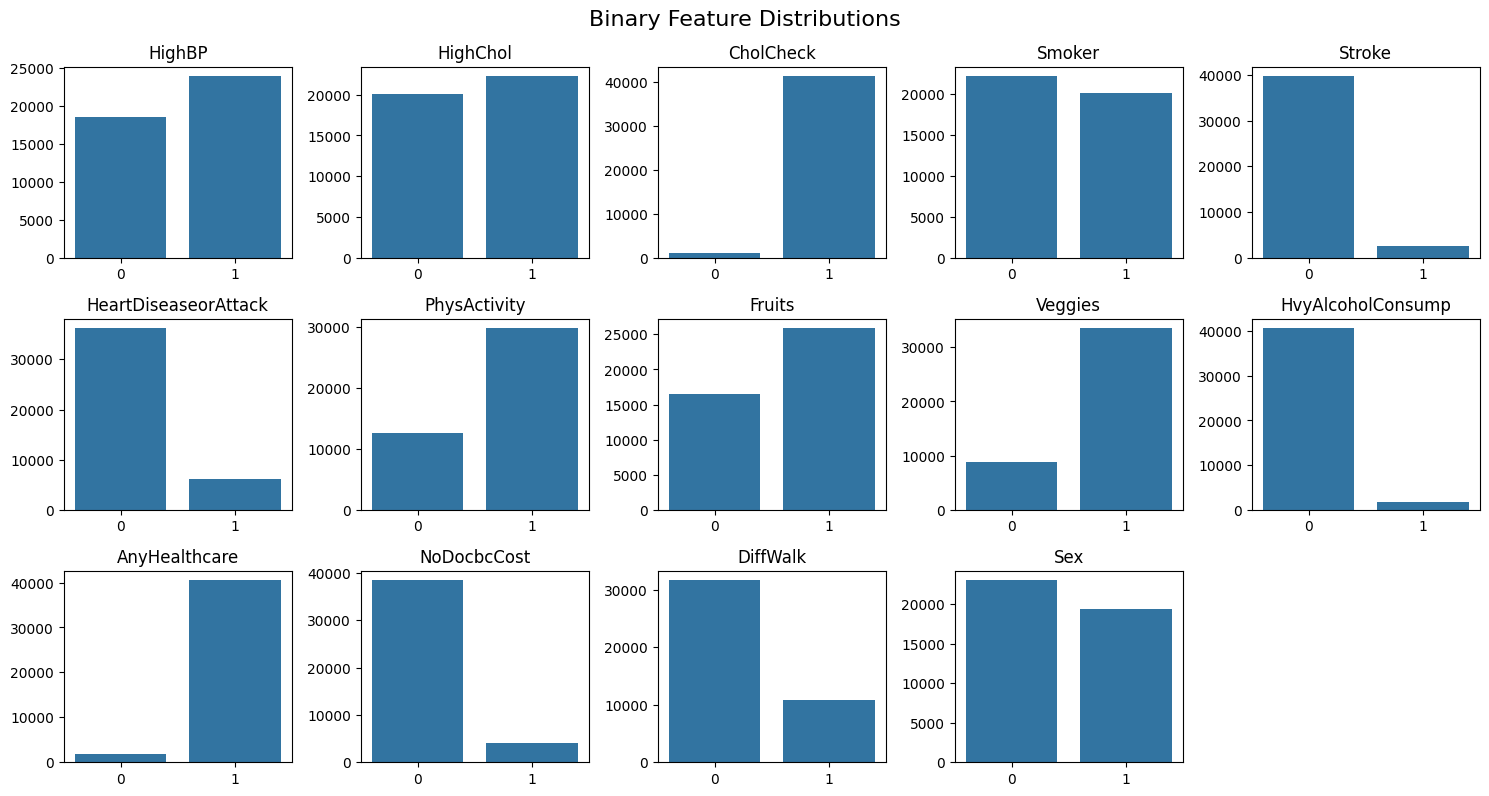

In [6]:
# Showing counts for binary features
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and col != 'Diabetes_binary']

plt.figure(figsize=(15, 10))
for i, col in enumerate(binary_cols, 1):
    plt.subplot(4, 5, i)
    sns.countplot(x=col, data=df)
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('')
    plt.tight_layout()

plt.suptitle("Binary Feature Distributions", y=1.02, fontsize=16)
plt.show()

1. HighBP & HighChol: A higher proportion of individuals reported high blood pressure and cholesterol, both major risk factors for diabetes.
2. CholCheck: Nearly all participants reported having had their cholesterol checked, indicating good preventive healthcare access.
3. Smoker: Smoking behavior is relatively balanced, though non-smokers are slightly more prevalent.
4. Stroke and HeartDiseaseorAttack: Both are rare events in the dataset. The majority did not report experiencing these conditions.
5. PhysActivity: A majority of the population is engaging in some form of physical activity, which reflects positively on general lifestyle practices.
6. Fruits & Veggies: Most respondents report consuming fruits and vegetables regularly, with vegetable consumption being particularly high.
7. HvyAlcoholConsump: Very few individuals reported heavy alcohol consumption, which is a positive lifestyle indicator in this context.
8. AnyHealthcare: Nearly the entire population has access to healthcare, with very few lacking it.
9. NoDocbcCost: Most participants did not report skipping doctor visits due to cost which again reflets a good access to care.
10. DiffWalk: Most individuals do not report difficulty walking, suggesting relatively good mobility across the population.
11. Sex: The dataset has a very slightly uneven distribution between the two gender categories, with a slight male majority

**Data Preprocessing**

To prepare the data for modelling 
* the target variable (Diabetes_binary) was separated from the features
* Numerical features like Age, BMI, GenHlth, MentHlth, PhysHlth, Education, and Income were identified for scaling which were then standardized using StandardScaler for ensuring consistent ranges across features.
* Binary and categorical features were left unchanged using 'passthrough' in the pipeline, to make them preserve their interpretability and logical structure
* the data was then split into training and testing sets using an 80:20 split, with startification on the target variable to preserve the class imbalance.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Define features and target
X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

# Reclassifying numeric and binary columns
numerical_cols = ['Age', 'BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Education', 'Income']
categorical_cols = [col for col in X.columns if col not in numerical_cols]

# Defining the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', 'passthrough', categorical_cols)
    ]
)

# Spliting into train/test (80/20), stratified to preserve class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Fitting transformer on training data, apply to train and test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [8]:
# Show shape and sample of processed data
print("Processed train shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("First 3 samples (scaled + binary passthrough):")
print(X_train_processed[:3])

Processed train shape: (33932, 21)
Processed test shape: (8483, 21)
First 3 samples (scaled + binary passthrough):
[[ 0.48982465 -1.38947861 -1.65060949 -0.45865786 -0.58006365  1.04700799
   1.0599396   0.          1.          1.          0.          0.
   0.          1.          0.          1.          0.          1.
   0.          0.          0.        ]
 [ 0.48982465  0.87278271  1.0348758  -0.45865786 -0.48096429  1.04700799
  -1.69163798  1.          1.          1.          1.          0.
   0.          1.          0.          1.          0.          1.
   0.          0.          1.        ]
 [ 0.48982465 -0.25834795  0.13971404 -0.21256858 -0.08456682 -0.88691189
   0.14274707  1.          1.          1.          1.          0.
   0.          1.          1.          1.          0.          1.
   0.          0.          1.        ]]


After the transformation, both training and test datatsets had 21 feature each ( 7 scaled numerical values and 14 binary features) and were ready to be fed into the models

**Correlation matrix**

To further explore the relationship between the features and diabetes, a correlation matrix was computed using all numeric features with binary target variable Diabetes_binary.

In [9]:
# Computing correlation matrix (includes target)
correlation_matrix = df.corr(numeric_only=True)

# Displaying top correlations with the target variable
target_corr = correlation_matrix['Diabetes_binary'].sort_values(ascending=False)
print(target_corr.head(6))

print("\nTop features negatively correlated with Diabetes_binary:")
print(target_corr.tail(5))

Diabetes_binary    1.000000
GenHlth            0.403320
HighBP             0.384567
HighChol           0.293386
BMI                0.288792
Age                0.276682
Name: Diabetes_binary, dtype: float64

Top features negatively correlated with Diabetes_binary:
Veggies             -0.074976
HvyAlcoholConsump   -0.096577
PhysActivity        -0.154211
Education           -0.169359
Income              -0.223148
Name: Diabetes_binary, dtype: float64


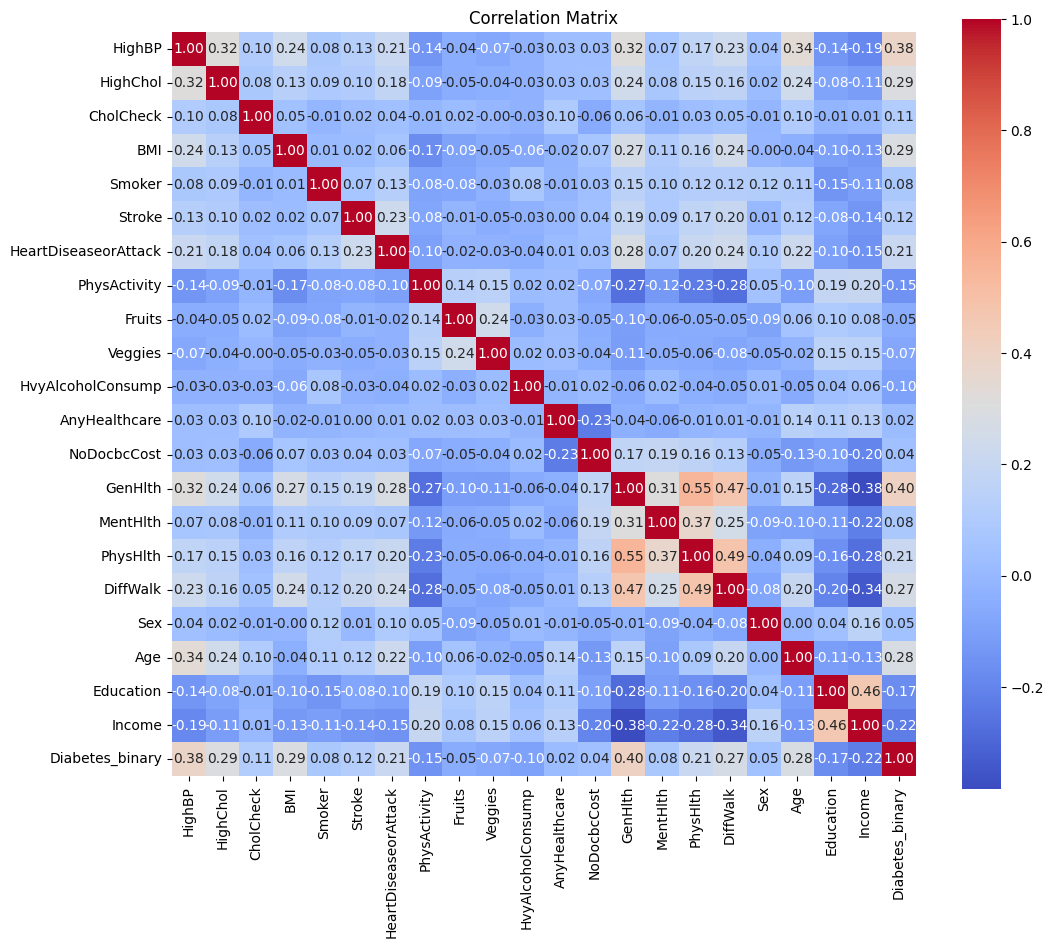

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title("Correlation Matrix")
plt.show()

The results from the correlation matrix are 
* Positive correlation
  
| Feature    | Correlation |
| ---------- | ----------- |
| `GenHlth`  | 0.403       |
| `HighBP`   | 0.385       |
| `HighChol` | 0.293       |
| `BMI`      | 0.289       |
| `Age`      | 0.277       |

These findings say what we already know from known medical assosciations like individuals with higher BMI, old age, poor general health amd conditions like blood pressure and cholestrol are more likely to have diabetes.

* Negative correlation

| Feature             | Correlation |
| ------------------- | ----------- |
| `Income`            | -0.223      |
| `Education`         | -0.169      |
| `PhysActivity`      | -0.154      |
| `HvyAlcoholConsump` | -0.097      |
| `Veggies`           | -0.075      |

This suggests that higer income and education levels along with physical activities and nutritional conscious lifestyle are associated with lower diabetes prevalence.

The heatmap of the correlation matrix visually highlights these relationships which shows the strength and direction of feature interaction.

**Relation between BMI and diabetes**


To understand the relation between target variable and one of the features we took BMI as the feature and looked into it

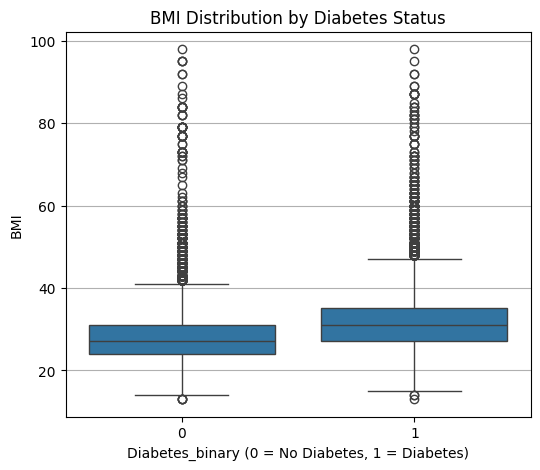

In [11]:
plt.figure(figsize=(6, 5))
sns.boxplot(x='Diabetes_binary', y='BMI', data=df)
plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes_binary (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("BMI")
plt.grid(True, axis='y')
plt.show()

This boxplot comparing BMI distributions across diabetic and non diabetic groups showed that people with diabetes have a notably higher median BMI than those without.

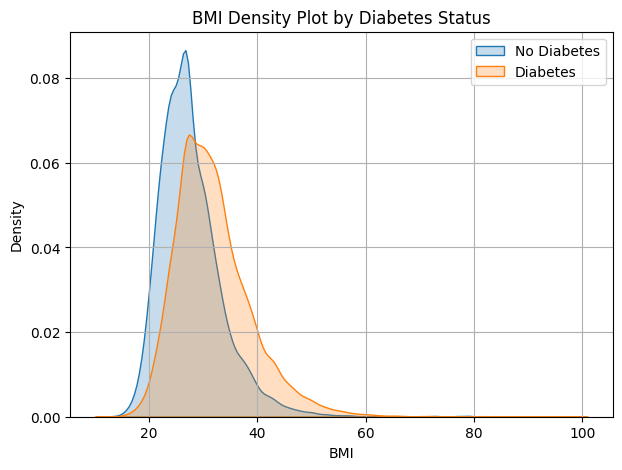

In [12]:
plt.figure(figsize=(7, 5))
sns.kdeplot(data=df[df['Diabetes_binary'] == 0], x='BMI', label='No Diabetes', fill=True)
sns.kdeplot(data=df[df['Diabetes_binary'] == 1], x='BMI', label='Diabetes', fill=True)
plt.title("BMI Density Plot by Diabetes Status")
plt.xlabel("BMI")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()

Also, the KDE(density) plot is showing a clear right shift in BMI distribution for diabetic individuals. While there is a  slight overlap between the curves, the diabetic group is concentrated more in the obese range showing a meaningful relation between BMI and diabetes.

In [13]:
mean_bmi = df.groupby('Diabetes_binary')['BMI'].mean()
print("Mean BMI by Diabetes Status:")
print(mean_bmi)

Mean BMI by Diabetes Status:
Diabetes_binary
0    27.799025
1    31.909479
Name: BMI, dtype: float64


The mean BMI values also confirm this 
* diabetic : 31.9
* non diabetic : 27.8

the roughly 4 average increase supports the strong relation between higher BMI in diabetic population. Also the broader BMI spread in the diabetic population suggests that while BMI is significant predictive factor it alone dosen't determine diabetes.

## Section 3: Model exploration to determine network topology (8 required)

Before the model training, the dataset must be split into training and testing subsets as this ensures the model's performance can be evaluated on data it hasn't seen during training. Also, checking class imbalance is crucial for binary classification problems like diabetes prediction as an imbalanced dataset can bias the model towards the mojarity class.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import random

seed = 1
np.random.seed(seed)
random.seed(seed)
tf.random.set_seed(seed)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=seed, stratify=y, shuffle=True
)

# Displaying class balance
print("Training dataset length:", len(X_train))
print("Testing dataset length:", len(X_test))
print("\n% of '1' in Training:", round(np.mean(y_train) * 100, 2), "%")
print("% of '1' in Test    :", round(np.mean(y_test) * 100, 2), "%")

Training dataset length: 28418
Testing dataset length: 13997

% of '1' in Training: 49.72 %
% of '1' in Test    : 49.72 %


The dataset is spllit into training(67 %) and testing (33 %) sets.

I used stratify = y to preserve the original ratio of diabetic and non-diabetic cases across both subsets. Without any startification, the model could recieeve a skewed distribution in the training or testing set.

The training set contains 28,418 samples and the test set contatins 13,997 samples and the class distribution in both thes sets is roughly 49.72 % for the positive class(1/diabetic), which is also almost close to a perfect 50-50 balance. This helps the model learn both classes fairly and makes metrics like accuracy more meaningful.++

**3.1 Main Objective**


The goal of this section is to experiment with a variety of neural network topologies and identify an architecture that can generalize well for the diabetes classification task. We test diffrerent combinations of hidden layers (both shallow and deep) to examine their effects on the model performance which ultimately selects the best performing modelbased on validation accuracy and other key metrics.

We explored eight different topologies (M1-M8) with incresing depth and width to observe underfitting, optimal capacirty and overfitting. These range from a simple 1 layer model(M1) to a deep 5 layer model(7)


**3.2 Model Configuration**

layer_configs = [

    [4],                      # M1 — Smallest network
    
    [8, 4],                   # M2 — Slightly deeper
    
    [16, 8, 4],               # M3
    
    [32, 16, 8],              # M4 — Best model
    
    [64, 32, 16, 8],          # M5
    
    [128, 64, 32, 16],        # M6
    
    [256, 128, 64, 32, 16],   # M7 — Deepest network
    
    [32, 32, 32]              # M8 — Wide and balanced
    
]

These configuration allows us to :
1. Start from a minimal baseline(m1) to understand how a small model behaves.
2. Gradually increase depth to explore the effect of network complexity.
3. Introduce wider architecture(m8) to test horizontal capacity over depth.
4. Observe signs of underfitting, good generalization or overfitting

**3.3 Training strategy**

Each model was trained using:

    Loss function: binary_crossentropy

    Optimizer: adam

    Early stopping (patience=10)

    Max epochs: 80

    Train/validation split: 80/20

The goal is to balance performance training stability while avoiding unnecessary overfitting. Also the training history being tracked for all models.


 Training Model M1 with layers: [4]
Epoch 1/80
889/889 [==============================] - 1s 894us/step - loss: 0.6397 - accuracy: 0.6700 - val_loss: 0.6057 - val_accuracy: 0.7061
Epoch 2/80
889/889 [==============================] - 1s 765us/step - loss: 0.5755 - accuracy: 0.7177 - val_loss: 0.5492 - val_accuracy: 0.7259
Epoch 3/80
889/889 [==============================] - 1s 755us/step - loss: 0.5393 - accuracy: 0.7299 - val_loss: 0.5394 - val_accuracy: 0.7313
Epoch 4/80
889/889 [==============================] - 1s 775us/step - loss: 0.5336 - accuracy: 0.7338 - val_loss: 0.5383 - val_accuracy: 0.7362
Epoch 5/80
889/889 [==============================] - 1s 770us/step - loss: 0.5311 - accuracy: 0.7358 - val_loss: 0.5371 - val_accuracy: 0.7376
Epoch 6/80
889/889 [==============================] - 1s 748us/step - loss: 0.5294 - accuracy: 0.7367 - val_loss: 0.5324 - val_accuracy: 0.7383
Epoch 7/80
889/889 [==============================] - 1s 766us/step - loss: 0.5284 - accuracy: 0.73

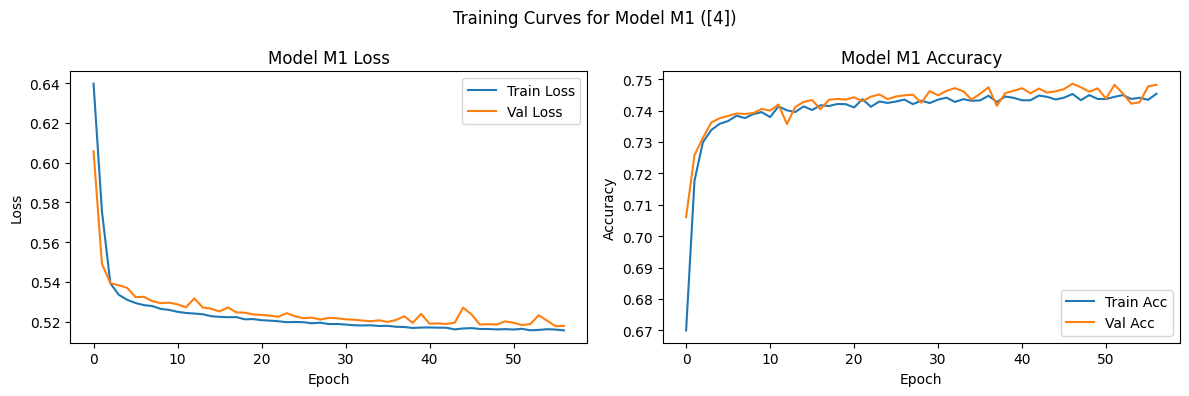


 Training Model M2 with layers: [8, 4]
Epoch 1/80
889/889 [==============================] - 1s 894us/step - loss: 0.5929 - accuracy: 0.6834 - val_loss: 0.5781 - val_accuracy: 0.6841
Epoch 2/80
889/889 [==============================] - 1s 812us/step - loss: 0.5423 - accuracy: 0.7282 - val_loss: 0.5409 - val_accuracy: 0.7313
Epoch 3/80
889/889 [==============================] - 1s 796us/step - loss: 0.5348 - accuracy: 0.7334 - val_loss: 0.5487 - val_accuracy: 0.7178
Epoch 4/80
889/889 [==============================] - 1s 802us/step - loss: 0.5317 - accuracy: 0.7343 - val_loss: 0.5308 - val_accuracy: 0.7387
Epoch 5/80
889/889 [==============================] - 1s 797us/step - loss: 0.5294 - accuracy: 0.7364 - val_loss: 0.5350 - val_accuracy: 0.7404
Epoch 6/80
889/889 [==============================] - 1s 784us/step - loss: 0.5271 - accuracy: 0.7390 - val_loss: 0.5347 - val_accuracy: 0.7428
Epoch 7/80
889/889 [==============================] - 1s 811us/step - loss: 0.5263 - accuracy: 0

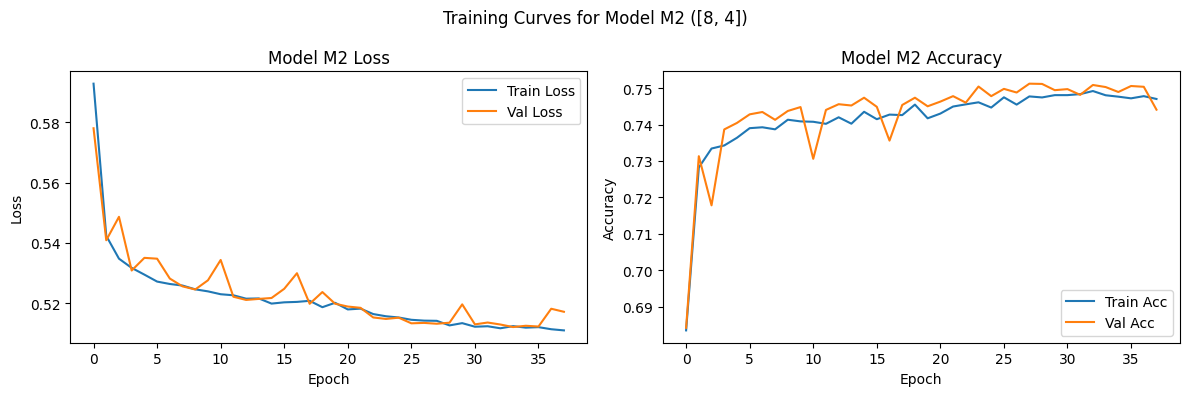


 Training Model M3 with layers: [16, 8, 4]
Epoch 1/80
889/889 [==============================] - 1s 925us/step - loss: 0.7701 - accuracy: 0.6682 - val_loss: 0.6117 - val_accuracy: 0.7029
Epoch 2/80
889/889 [==============================] - 1s 844us/step - loss: 0.5812 - accuracy: 0.7239 - val_loss: 0.5642 - val_accuracy: 0.7355
Epoch 3/80
889/889 [==============================] - 1s 828us/step - loss: 0.5533 - accuracy: 0.7367 - val_loss: 0.5546 - val_accuracy: 0.7326
Epoch 4/80
889/889 [==============================] - 1s 824us/step - loss: 0.5400 - accuracy: 0.7380 - val_loss: 0.5356 - val_accuracy: 0.7442
Epoch 5/80
889/889 [==============================] - 1s 842us/step - loss: 0.5323 - accuracy: 0.7418 - val_loss: 0.5356 - val_accuracy: 0.7442
Epoch 6/80
889/889 [==============================] - 1s 839us/step - loss: 0.5273 - accuracy: 0.7434 - val_loss: 0.5381 - val_accuracy: 0.7433
Epoch 7/80
889/889 [==============================] - 1s 837us/step - loss: 0.5248 - accurac

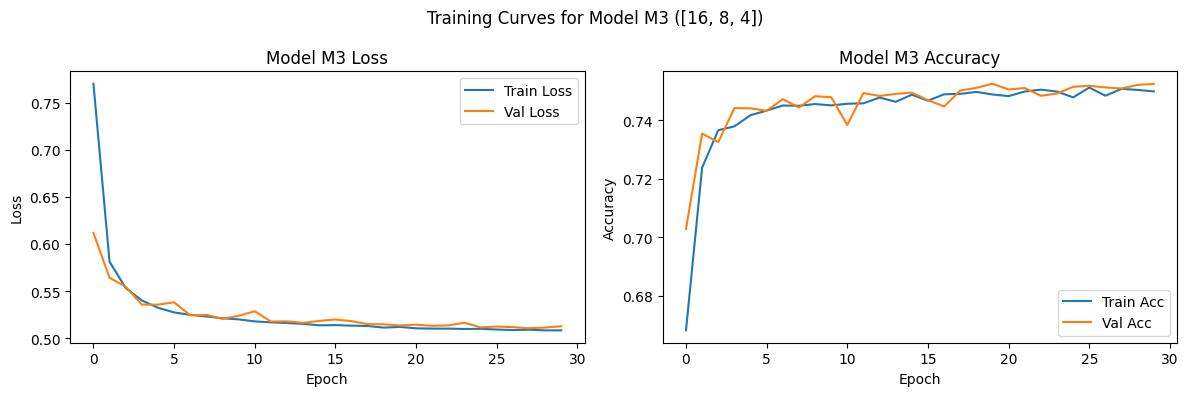


 Training Model M4 with layers: [32, 16, 8]
Epoch 1/80
889/889 [==============================] - 1s 909us/step - loss: 0.5529 - accuracy: 0.7136 - val_loss: 0.5533 - val_accuracy: 0.7193
Epoch 2/80
889/889 [==============================] - 1s 829us/step - loss: 0.5289 - accuracy: 0.7343 - val_loss: 0.5242 - val_accuracy: 0.7367
Epoch 3/80
889/889 [==============================] - 1s 818us/step - loss: 0.5228 - accuracy: 0.7366 - val_loss: 0.5320 - val_accuracy: 0.7364
Epoch 4/80
889/889 [==============================] - 1s 822us/step - loss: 0.5206 - accuracy: 0.7392 - val_loss: 0.5199 - val_accuracy: 0.7427
Epoch 5/80
889/889 [==============================] - 1s 824us/step - loss: 0.5178 - accuracy: 0.7417 - val_loss: 0.5206 - val_accuracy: 0.7411
Epoch 6/80
889/889 [==============================] - 1s 824us/step - loss: 0.5161 - accuracy: 0.7438 - val_loss: 0.5249 - val_accuracy: 0.7397
Epoch 7/80
889/889 [==============================] - 1s 820us/step - loss: 0.5148 - accura

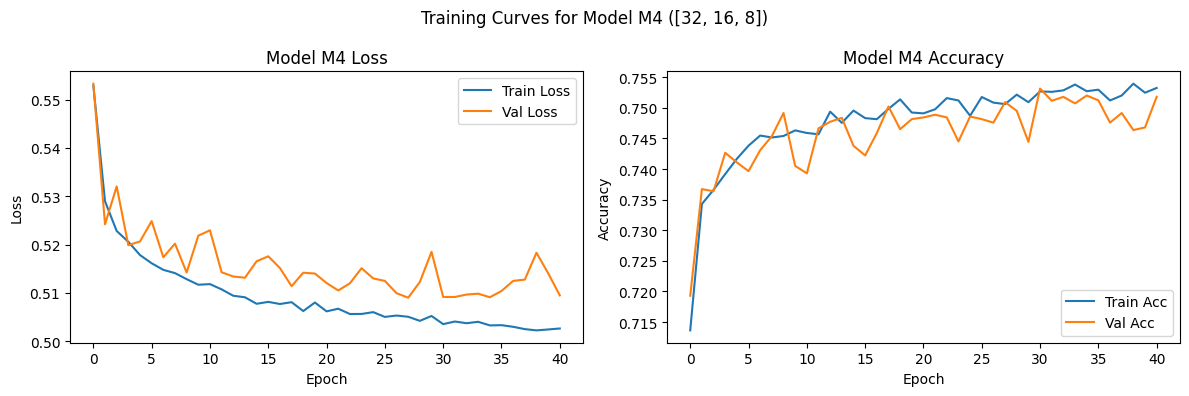


 Training Model M5 with layers: [64, 32, 16, 8]
Epoch 1/80
889/889 [==============================] - 1s 938us/step - loss: 0.5595 - accuracy: 0.7084 - val_loss: 0.5512 - val_accuracy: 0.7265
Epoch 2/80
889/889 [==============================] - 1s 859us/step - loss: 0.5288 - accuracy: 0.7331 - val_loss: 0.5284 - val_accuracy: 0.7414
Epoch 3/80
889/889 [==============================] - 1s 848us/step - loss: 0.5230 - accuracy: 0.7358 - val_loss: 0.5406 - val_accuracy: 0.7315
Epoch 4/80
889/889 [==============================] - 1s 855us/step - loss: 0.5213 - accuracy: 0.7371 - val_loss: 0.5186 - val_accuracy: 0.7452
Epoch 5/80
889/889 [==============================] - 1s 846us/step - loss: 0.5184 - accuracy: 0.7402 - val_loss: 0.5277 - val_accuracy: 0.7349
Epoch 6/80
889/889 [==============================] - 1s 848us/step - loss: 0.5165 - accuracy: 0.7448 - val_loss: 0.5277 - val_accuracy: 0.7379
Epoch 7/80
889/889 [==============================] - 1s 848us/step - loss: 0.5152 - ac

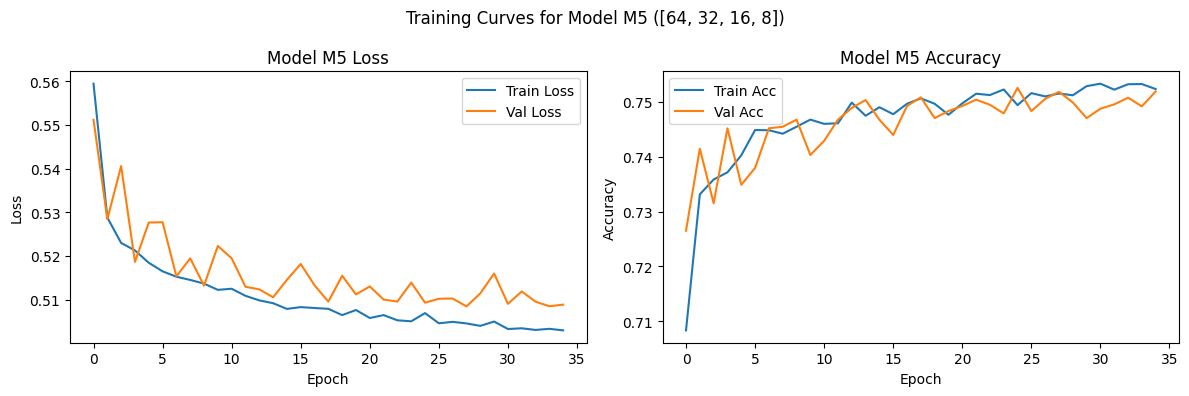


 Training Model M6 with layers: [128, 64, 32, 16]
Epoch 1/80
889/889 [==============================] - 1s 976us/step - loss: 0.5540 - accuracy: 0.7152 - val_loss: 0.5498 - val_accuracy: 0.7224
Epoch 2/80
889/889 [==============================] - 1s 873us/step - loss: 0.5307 - accuracy: 0.7321 - val_loss: 0.5315 - val_accuracy: 0.7367
Epoch 3/80
889/889 [==============================] - 1s 863us/step - loss: 0.5236 - accuracy: 0.7372 - val_loss: 0.5364 - val_accuracy: 0.7349
Epoch 4/80
889/889 [==============================] - 1s 897us/step - loss: 0.5209 - accuracy: 0.7397 - val_loss: 0.5207 - val_accuracy: 0.7429
Epoch 5/80
889/889 [==============================] - 1s 867us/step - loss: 0.5186 - accuracy: 0.7406 - val_loss: 0.5277 - val_accuracy: 0.7362
Epoch 6/80
889/889 [==============================] - 1s 868us/step - loss: 0.5160 - accuracy: 0.7440 - val_loss: 0.5249 - val_accuracy: 0.7395
Epoch 7/80
889/889 [==============================] - 1s 870us/step - loss: 0.5155 - 

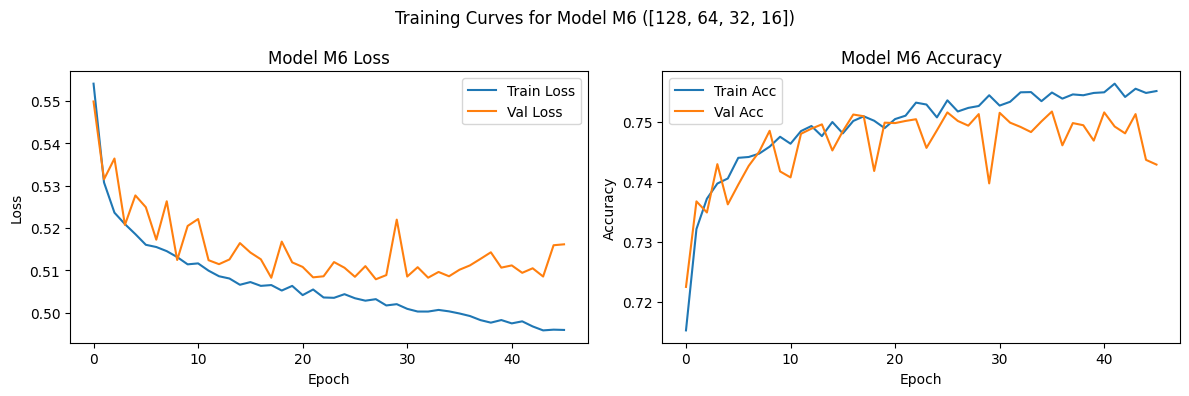


 Training Model M7 with layers: [256, 128, 64, 32, 16]
Epoch 1/80
889/889 [==============================] - 2s 1ms/step - loss: 0.5525 - accuracy: 0.7157 - val_loss: 0.5551 - val_accuracy: 0.7219
Epoch 2/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5302 - accuracy: 0.7341 - val_loss: 0.5271 - val_accuracy: 0.7383
Epoch 3/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5229 - accuracy: 0.7386 - val_loss: 0.5359 - val_accuracy: 0.7319
Epoch 4/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5208 - accuracy: 0.7402 - val_loss: 0.5185 - val_accuracy: 0.7436
Epoch 5/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5181 - accuracy: 0.7403 - val_loss: 0.5341 - val_accuracy: 0.7265
Epoch 6/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5159 - accuracy: 0.7440 - val_loss: 0.5198 - val_accuracy: 0.7382
Epoch 7/80
889/889 [==============================] - 1s 1ms/step - loss: 0.5148 - accuracy:

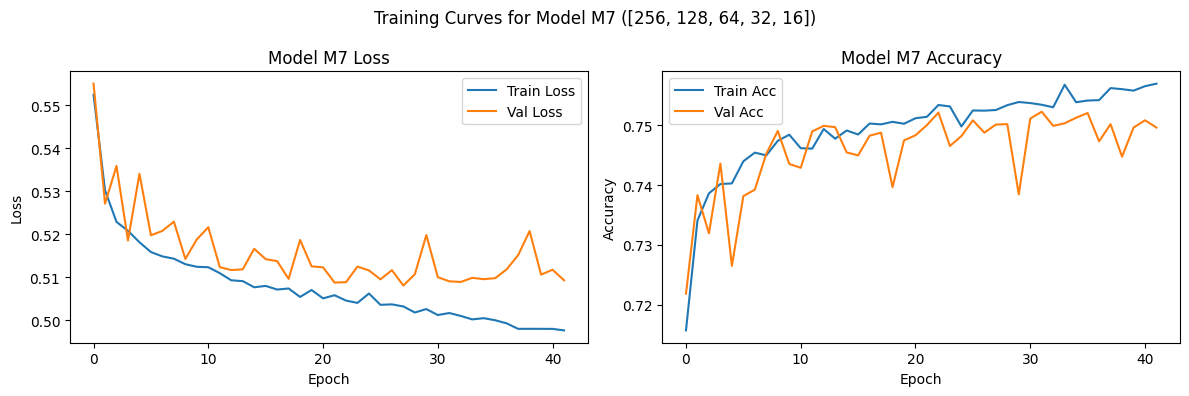


 Training Model M8 with layers: [32, 32, 32]
Epoch 1/80
889/889 [==============================] - 1s 910us/step - loss: 0.5574 - accuracy: 0.7115 - val_loss: 0.5558 - val_accuracy: 0.7109
Epoch 2/80
889/889 [==============================] - 1s 936us/step - loss: 0.5299 - accuracy: 0.7341 - val_loss: 0.5269 - val_accuracy: 0.7389
Epoch 3/80
889/889 [==============================] - 1s 996us/step - loss: 0.5228 - accuracy: 0.7381 - val_loss: 0.5359 - val_accuracy: 0.7329
Epoch 4/80
889/889 [==============================] - 1s 862us/step - loss: 0.5204 - accuracy: 0.7399 - val_loss: 0.5196 - val_accuracy: 0.7454
Epoch 5/80
889/889 [==============================] - 1s 832us/step - loss: 0.5177 - accuracy: 0.7432 - val_loss: 0.5197 - val_accuracy: 0.7446
Epoch 6/80
889/889 [==============================] - 1s 835us/step - loss: 0.5163 - accuracy: 0.7440 - val_loss: 0.5238 - val_accuracy: 0.7388
Epoch 7/80
889/889 [==============================] - 1s 821us/step - loss: 0.5155 - accur

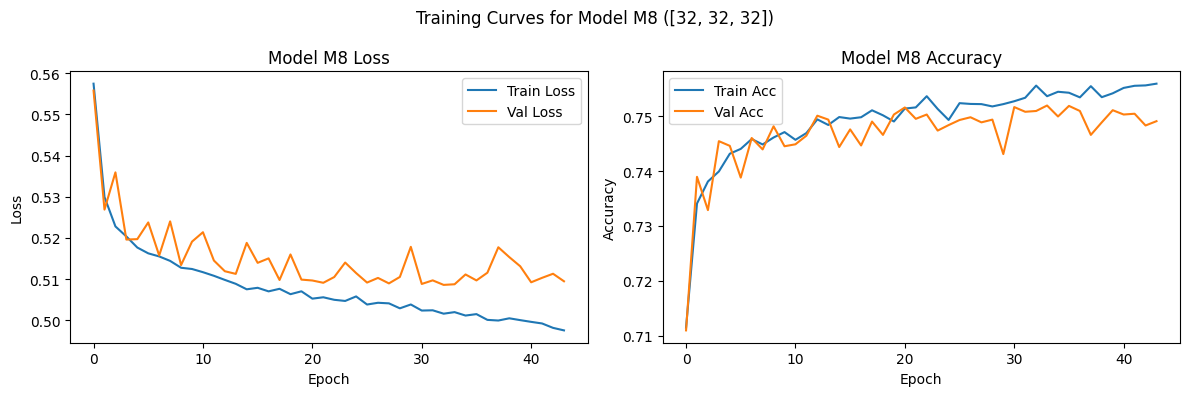

In [15]:
# Defining 8 model configurations to explore
layer_configs = [
    [4],                      # M1 — Minimal network
    [8, 4],                   # M2
    [16, 8, 4],               # M3
    [32, 16, 8],              # M4 — Moderate depth
    [64, 32, 16, 8],          # M5
    [128, 64, 32, 16],        # M6
    [256, 128, 64, 32, 16],   # M7 — Deep
    [32, 32, 32]              # M8 — Wide and balanced
]

results = []
best_val_accuracy = 0
best_config = None

for i, config in enumerate(layer_configs, start=1):
    print(f"\n Training Model M{i} with layers: {config}")

    # Building the model
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    for units in config:
        model.add(Dense(units, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))  # Binary classification

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Using Early stopping for avoiding overfitting
    early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=80,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluating best validation accuracy
    max_val_acc = max(history.history['val_accuracy'])
    print(f" Max Validation Accuracy for Model M{i}: {max_val_acc:.4f}")

    # Predict on test data
    y_pred_prob = model.predict(X_test)
    y_pred = (y_pred_prob > 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        'Model': f'M{i}',
        'Layers': str(config),
        'Val_Accuracy': max_val_acc,
        'Test_Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1_Score': f1
    })

    # Plot training curves
    plt.figure(figsize=(12, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Model M{i} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title(f'Model M{i} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.suptitle(f"Training Curves for Model M{i} ({config})")
    plt.tight_layout()
    plt.show()

    # Track best model
    if max_val_acc > best_val_accuracy:
        best_val_accuracy = max_val_acc
        best_config = config

**3.4 Performance Summary**

After training, we collected the best validation and test metrics for each model:

In [16]:
# Showing the best model info
print(f"\n Best model: Layers {best_config} with validation accuracy: {best_val_accuracy:.4f}")

# Displaying summary table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Val_Accuracy', ascending=False)
print("\n Model Performance Summary:")
print(results_df)


 Best model: Layers [32, 16, 8] with validation accuracy: 0.7532

 Model Performance Summary:
  Model                  Layers  Val_Accuracy  Test_Accuracy  Precision  \
3    M4             [32, 16, 8]      0.753161       0.753161   0.727355   
2    M3              [16, 8, 4]      0.752590       0.752590   0.732942   
4    M5         [64, 32, 16, 8]      0.752518       0.752518   0.719618   
6    M7  [256, 128, 64, 32, 16]      0.752233       0.752233   0.727013   
7    M8            [32, 32, 32]      0.751947       0.751947   0.724129   
5    M6       [128, 64, 32, 16]      0.751733       0.751733   0.727772   
1    M2                  [8, 4]      0.751232       0.751232   0.728720   
0    M1                     [4]      0.748589       0.748589   0.734205   

     Recall  F1_Score  
3  0.805432  0.764405  
2  0.790343  0.760561  
4  0.822819  0.767766  
6  0.803276  0.763244  
7  0.809455  0.764419  
5  0.799828  0.762100  
1  0.795948  0.760852  
0  0.774824  0.753968  


**3.5 Analysis And interpretation**

1. M1:[4]
   * Acts as the baseline model.
   * achieves roughly 74.86% validation accuracy.
   * highesh precision which suggests good performance on positive class.
   * but the recall and F1 are lower which indicates its missing more positives.


2. M2:[8,4]
   * small increase in performance.
   * smoother training curves and less noise
   * modest improvement in recall and F1.


3. M3: [16,8,4]
   * first significantly better model.
   * Accuracy and F1 both improve, reflecting increased capacuity.


4. M4: [32,16,8]
    * Achieved the best validation accuracy: 0.7532.
    * strong performance across all metrics.
    * Smooth and stable learning.
    * no signs of overfitting, unlike deeper models.


5. M5: [64,32,16,8] 
    * similar accuracy to m4, but slightly better F1 score.
    * Incresed depth gives slight gains but is adding training complexity.


6. M6 and M8: Deep Networks.
    * Performance is starting to go plateau.
    * validation accuracy doesn'[t improve.
    * Training is becoming less stable, with some overfitting signs in loss curve.


7. M8: [32,32,32]
    * Wide network
    * Good f1 and recall but no clear or visible advantage over M4/M5

## Section 4: Hyperparameter Investigation.

**4.1 Batch Size Investigation**

Batch size determines how many samples are processed before a model is updated. To explore its impact,we are testing a range of batch sizes: 16,32,64,128,256,512,1024 and 2048. These batches choosen to be spanned across small(16-64), medium(128-512) and large 91024_2048) batches where i can capture variations in training stability, convergence speed, and generaliztion. Small batches often improve generalizatio but can be noisy whereas large ones being faster but risk overfitting. each setup used same architecture,early stopping and upto 80 epochs. Reslts were evaluated absed on validation accuracy, learning trnds and final performance to identify the best batch size.

### Batch Size Exploration ###

Training with batch size: 16
Epoch 1/80
1777/1777 [==============================] - 2s 850us/step - loss: 0.5655 - accuracy: 0.7084 - val_loss: 0.5435 - val_accuracy: 0.7238
Epoch 2/80
1777/1777 [==============================] - 1s 822us/step - loss: 0.5303 - accuracy: 0.7352 - val_loss: 0.5350 - val_accuracy: 0.7348
Epoch 3/80
1777/1777 [==============================] - 1s 811us/step - loss: 0.5251 - accuracy: 0.7357 - val_loss: 0.5265 - val_accuracy: 0.7399
Epoch 4/80
1777/1777 [==============================] - 1s 804us/step - loss: 0.5240 - accuracy: 0.7370 - val_loss: 0.5252 - val_accuracy: 0.7392
Epoch 5/80
1777/1777 [==============================] - 1s 820us/step - loss: 0.5197 - accuracy: 0.7406 - val_loss: 0.5168 - val_accuracy: 0.7434
Epoch 6/80
1777/1777 [==============================] - 1s 819us/step - loss: 0.5184 - accuracy: 0.7413 - val_loss: 0.5303 - val_accuracy: 0.7333
Epoch 7/80
1777/1777 [==============================] - 1s 820u

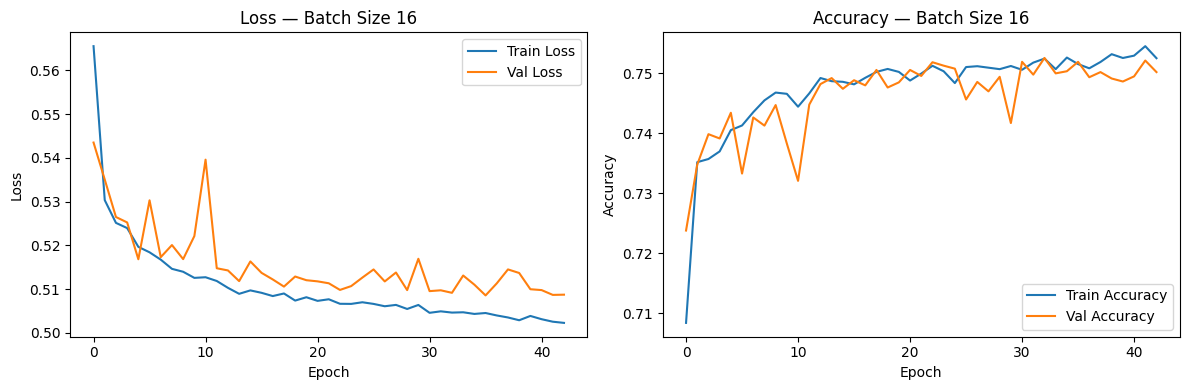


Training with batch size: 32
Epoch 1/80
889/889 [==============================] - 1s 927us/step - loss: 0.5839 - accuracy: 0.6971 - val_loss: 0.5542 - val_accuracy: 0.7159
Epoch 2/80
889/889 [==============================] - 1s 838us/step - loss: 0.5321 - accuracy: 0.7319 - val_loss: 0.5293 - val_accuracy: 0.7384
Epoch 3/80
889/889 [==============================] - 1s 821us/step - loss: 0.5244 - accuracy: 0.7365 - val_loss: 0.5359 - val_accuracy: 0.7329
Epoch 4/80
889/889 [==============================] - 1s 821us/step - loss: 0.5215 - accuracy: 0.7388 - val_loss: 0.5204 - val_accuracy: 0.7413
Epoch 5/80
889/889 [==============================] - 1s 840us/step - loss: 0.5199 - accuracy: 0.7408 - val_loss: 0.5224 - val_accuracy: 0.7385
Epoch 6/80
889/889 [==============================] - 1s 838us/step - loss: 0.5172 - accuracy: 0.7417 - val_loss: 0.5281 - val_accuracy: 0.7342
Epoch 7/80
889/889 [==============================] - 1s 835us/step - loss: 0.5162 - accuracy: 0.7453 - va

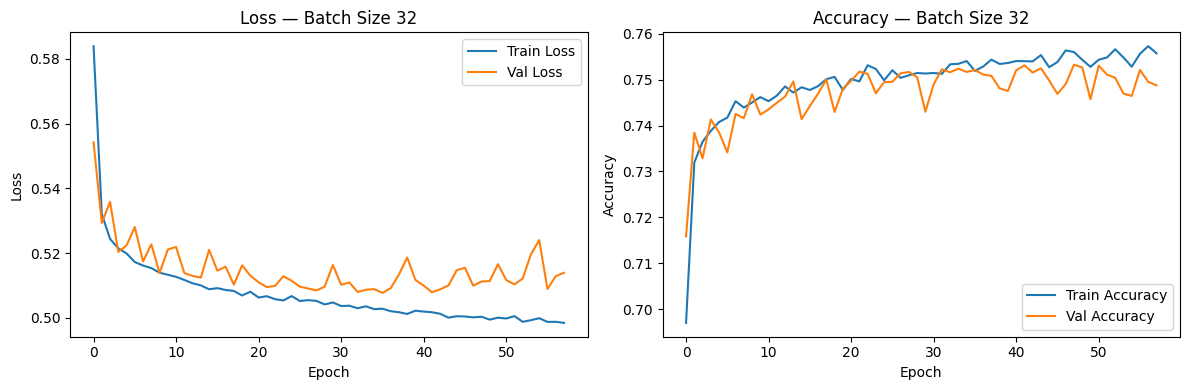


Training with batch size: 64
Epoch 1/80
445/445 [==============================] - 1s 1ms/step - loss: 0.5887 - accuracy: 0.6885 - val_loss: 0.5603 - val_accuracy: 0.7094
Epoch 2/80
445/445 [==============================] - 0s 850us/step - loss: 0.5320 - accuracy: 0.7305 - val_loss: 0.5301 - val_accuracy: 0.7361
Epoch 3/80
445/445 [==============================] - 0s 867us/step - loss: 0.5248 - accuracy: 0.7373 - val_loss: 0.5339 - val_accuracy: 0.7354
Epoch 4/80
445/445 [==============================] - 0s 861us/step - loss: 0.5222 - accuracy: 0.7395 - val_loss: 0.5227 - val_accuracy: 0.7374
Epoch 5/80
445/445 [==============================] - 0s 865us/step - loss: 0.5208 - accuracy: 0.7400 - val_loss: 0.5300 - val_accuracy: 0.7256
Epoch 6/80
445/445 [==============================] - 0s 866us/step - loss: 0.5201 - accuracy: 0.7402 - val_loss: 0.5196 - val_accuracy: 0.7402
Epoch 7/80
445/445 [==============================] - 0s 862us/step - loss: 0.5186 - accuracy: 0.7421 - val_

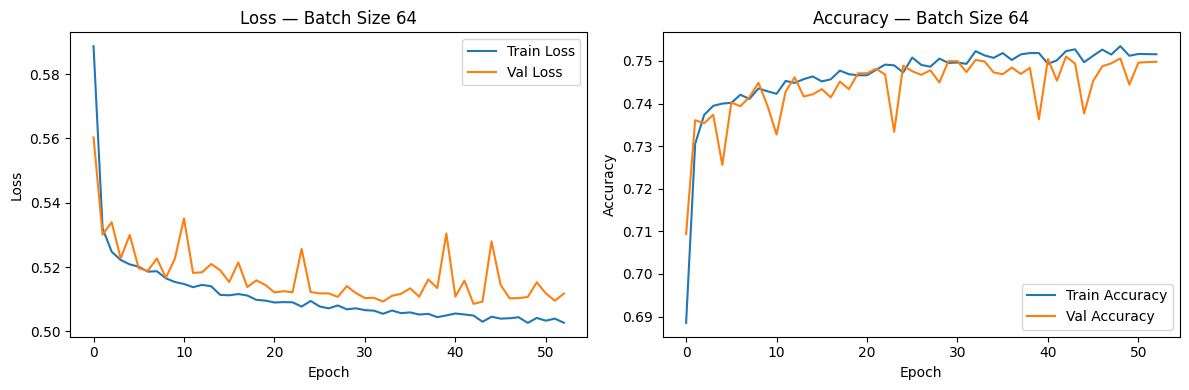


Training with batch size: 128
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6712 - accuracy: 0.6243 - val_loss: 0.6333 - val_accuracy: 0.7034
Epoch 2/80
223/223 [==============================] - 0s 979us/step - loss: 0.6125 - accuracy: 0.7132 - val_loss: 0.5992 - val_accuracy: 0.7257
Epoch 3/80
223/223 [==============================] - 0s 926us/step - loss: 0.5870 - accuracy: 0.7316 - val_loss: 0.5830 - val_accuracy: 0.7290
Epoch 4/80
223/223 [==============================] - 0s 858us/step - loss: 0.5707 - accuracy: 0.7390 - val_loss: 0.5664 - val_accuracy: 0.7398
Epoch 5/80
223/223 [==============================] - 0s 855us/step - loss: 0.5586 - accuracy: 0.7411 - val_loss: 0.5560 - val_accuracy: 0.7414
Epoch 6/80
223/223 [==============================] - 0s 924us/step - loss: 0.5499 - accuracy: 0.7427 - val_loss: 0.5493 - val_accuracy: 0.7433
Epoch 7/80
223/223 [==============================] - 0s 857us/step - loss: 0.5431 - accuracy: 0.7434 - val

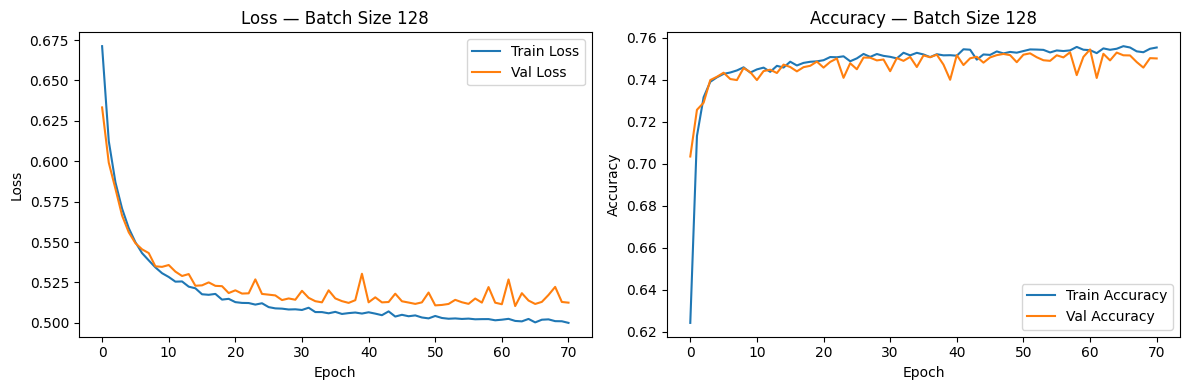


Training with batch size: 256
Epoch 1/80
112/112 [==============================] - 1s 2ms/step - loss: 0.6403 - accuracy: 0.6307 - val_loss: 0.5606 - val_accuracy: 0.7132
Epoch 2/80
112/112 [==============================] - 0s 1ms/step - loss: 0.5476 - accuracy: 0.7201 - val_loss: 0.5416 - val_accuracy: 0.7249
Epoch 3/80
112/112 [==============================] - 0s 988us/step - loss: 0.5335 - accuracy: 0.7298 - val_loss: 0.5310 - val_accuracy: 0.7363
Epoch 4/80
112/112 [==============================] - 0s 993us/step - loss: 0.5275 - accuracy: 0.7338 - val_loss: 0.5281 - val_accuracy: 0.7376
Epoch 5/80
112/112 [==============================] - 0s 995us/step - loss: 0.5251 - accuracy: 0.7354 - val_loss: 0.5282 - val_accuracy: 0.7382
Epoch 6/80
112/112 [==============================] - 0s 997us/step - loss: 0.5222 - accuracy: 0.7380 - val_loss: 0.5315 - val_accuracy: 0.7362
Epoch 7/80
112/112 [==============================] - 0s 992us/step - loss: 0.5213 - accuracy: 0.7386 - val_l

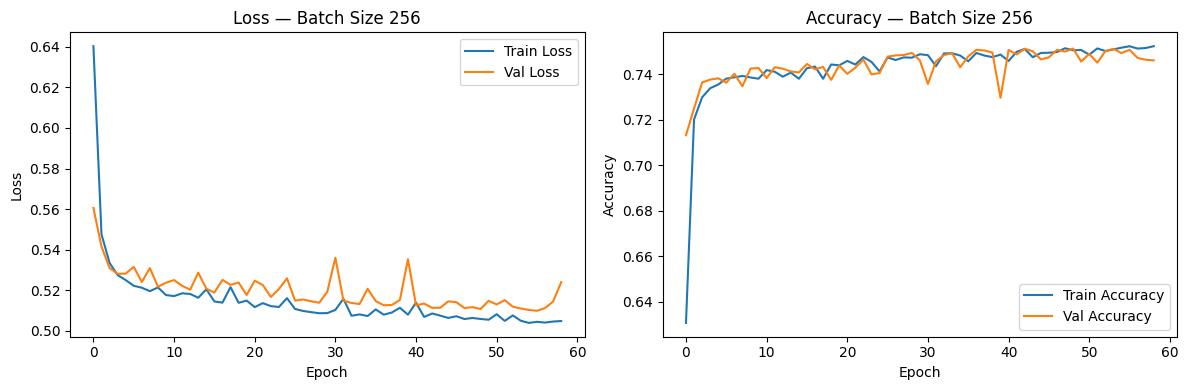


Training with batch size: 512
Epoch 1/80
56/56 [==============================] - 1s 3ms/step - loss: 0.7095 - accuracy: 0.6415 - val_loss: 0.5924 - val_accuracy: 0.6924
Epoch 2/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5750 - accuracy: 0.7016 - val_loss: 0.5712 - val_accuracy: 0.6965
Epoch 3/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5542 - accuracy: 0.7187 - val_loss: 0.5509 - val_accuracy: 0.7175
Epoch 4/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5411 - accuracy: 0.7280 - val_loss: 0.5420 - val_accuracy: 0.7317
Epoch 5/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5334 - accuracy: 0.7337 - val_loss: 0.5343 - val_accuracy: 0.7356
Epoch 6/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5275 - accuracy: 0.7362 - val_loss: 0.5308 - val_accuracy: 0.7379
Epoch 7/80
56/56 [==============================] - 0s 1ms/step - loss: 0.5238 - accuracy: 0.7383 - val_loss: 0.5273 - val_accura

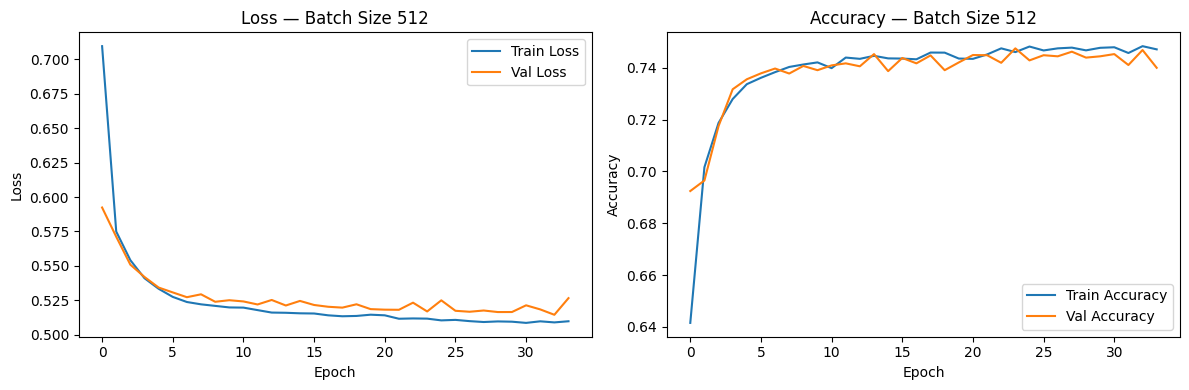


Training with batch size: 1024
Epoch 1/80
28/28 [==============================] - 1s 5ms/step - loss: 0.7760 - accuracy: 0.5163 - val_loss: 0.6831 - val_accuracy: 0.5664
Epoch 2/80
28/28 [==============================] - 0s 2ms/step - loss: 0.6736 - accuracy: 0.5851 - val_loss: 0.6633 - val_accuracy: 0.6145
Epoch 3/80
28/28 [==============================] - 0s 2ms/step - loss: 0.6521 - accuracy: 0.6287 - val_loss: 0.6419 - val_accuracy: 0.6446
Epoch 4/80
28/28 [==============================] - 0s 2ms/step - loss: 0.6276 - accuracy: 0.6632 - val_loss: 0.6137 - val_accuracy: 0.6858
Epoch 5/80
28/28 [==============================] - 0s 2ms/step - loss: 0.5935 - accuracy: 0.6967 - val_loss: 0.5749 - val_accuracy: 0.7157
Epoch 6/80
28/28 [==============================] - 0s 2ms/step - loss: 0.5641 - accuracy: 0.7170 - val_loss: 0.5559 - val_accuracy: 0.7225
Epoch 7/80
28/28 [==============================] - 0s 2ms/step - loss: 0.5497 - accuracy: 0.7237 - val_loss: 0.5467 - val_accur

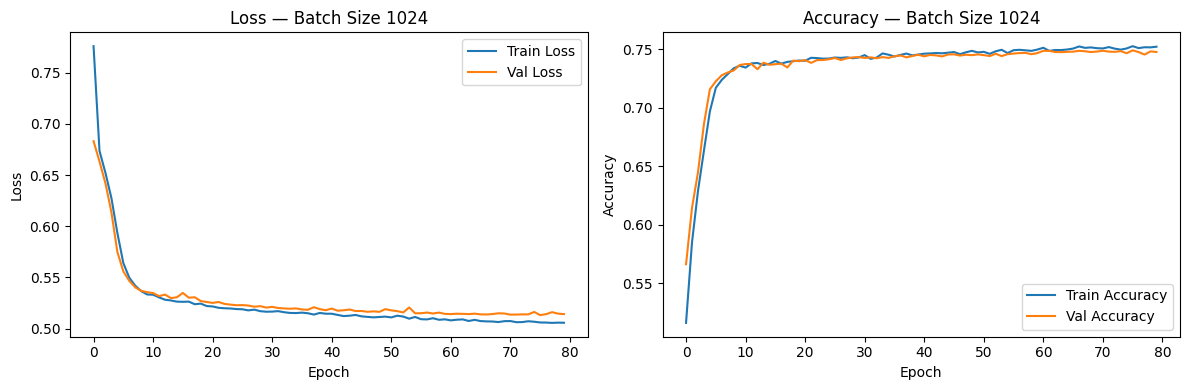


Training with batch size: 2048
Epoch 1/80
14/14 [==============================] - 1s 9ms/step - loss: 0.7305 - accuracy: 0.5874 - val_loss: 0.6482 - val_accuracy: 0.6299
Epoch 2/80
14/14 [==============================] - 0s 2ms/step - loss: 0.6151 - accuracy: 0.6640 - val_loss: 0.5907 - val_accuracy: 0.6839
Epoch 3/80
14/14 [==============================] - 0s 2ms/step - loss: 0.5888 - accuracy: 0.6855 - val_loss: 0.5774 - val_accuracy: 0.6920
Epoch 4/80
14/14 [==============================] - 0s 2ms/step - loss: 0.5754 - accuracy: 0.6961 - val_loss: 0.5663 - val_accuracy: 0.7084
Epoch 5/80
14/14 [==============================] - 0s 3ms/step - loss: 0.5642 - accuracy: 0.7069 - val_loss: 0.5560 - val_accuracy: 0.7135
Epoch 6/80
14/14 [==============================] - 0s 2ms/step - loss: 0.5547 - accuracy: 0.7158 - val_loss: 0.5503 - val_accuracy: 0.7184
Epoch 7/80
14/14 [==============================] - 0s 2ms/step - loss: 0.5478 - accuracy: 0.7194 - val_loss: 0.5438 - val_accur

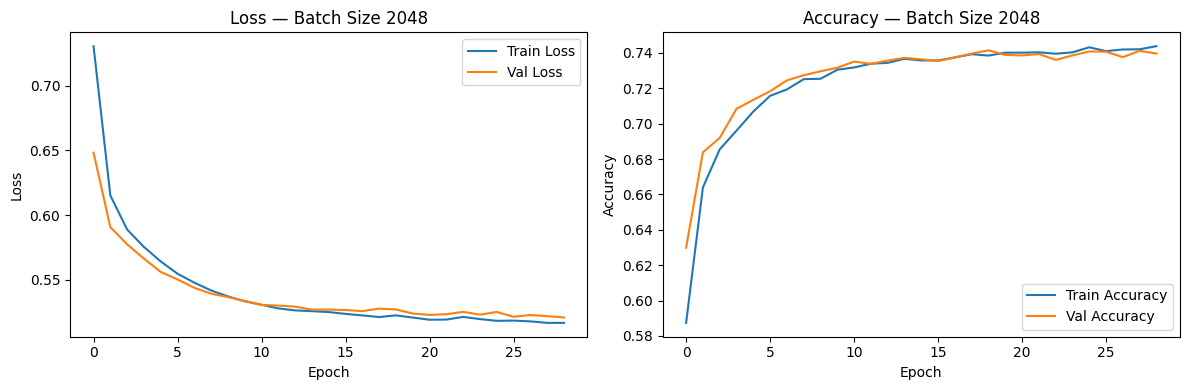


Best batch size: 128 with Validation Accuracy: 0.7544


In [17]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.regularizers import l2
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- 4.1 Batch Size Investigation ---
batch_sizes = [16, 32, 64, 128, 256, 512, 1024, 2048]

best_val_accuracy = 0
best_batch = None

print("### Batch Size Exploration ###")
for bs in batch_sizes:
    print(f"\nTraining with batch size: {bs}")

    model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    ])


    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=80,
        batch_size=bs,
        callbacks=[early_stop],
        verbose=1
    )

    max_val_acc = max(history.history['val_accuracy'])
    print(f"Max validation accuracy for batch size {bs}: {max_val_acc:.4f}")

    if max_val_acc > best_val_accuracy:
        best_val_accuracy = max_val_acc
        best_batch = bs

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss — Batch Size {bs}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy — Batch Size {bs}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

print(f"\nBest batch size: {best_batch} with Validation Accuracy: {best_val_accuracy:.4f}")

Output summary 

1. Batch size 16
    * Max validation accuracy : 0.7526
    * validation loss decreases with fluctuations and accuracy rises steadily
2. Batch size 32
    * Max validation accuracy: 0.7532
    * Stable training with smoother validation curve
3. Batch size 64
    * Max validation accuracy : 0.7510
    * has more volatile validation loss than smaller batches
4. Batch size 128
   * Max validation accuracy: 0.7544 (being the best one)
   * strong performance with smooth convergence over 71 epochs
5. Batch size 256
   * max validation accuracy : 0.7512
   * Slightly less stable with accuracy fluctuations
6. Batch size 512
   * max validation accuracy: 0.7475
   * More variance in validation metrics.
7. Batch size 1024
   * Max validation accuracy: 0.7489
   * model trained to full 80 epochs with validation slightly degraded over the end
8. Batch size 2048
   * Max validation accuracy: 0.7415
   * Less stable with early stopping at 29 epochs.

* Smaller batch sizes provided more frequent weight updates allowing for fine grained learning which however, came with the cost of increased training time, They performed well.
* Larger batch sizes resulted in faster training but less precise convergence,as shown by thier fluctuating validation curves and slightly lower accuracy. Notably 2048 stopped at 29 epochs due to unstable generation.
* The sweet spot was batch size 128, which achieved the highest validation accuracy with stable training curves and efficient convergence. It balanced training efficiency with generalization, making it the best batch size for this model dataset. 

The best four performing batch sizes were 32, 64, 128, and 256.(later for grid search)

**4.2 Optimizer Investigation**

After identifying the optimal batch size, I explored how diffrent optimizers affect model performance. Optimizers are crucial as they determine how the model updates weights during training, impacting convergence speed, stability and accuracy. I selected Admam,SDG and RMSprop as they represent three widely used and fundamentally different optimization strategies.

Sdg being a classic baseline with simple gradient updates, RMSprop is known for adapting learning rates per parameters to hanle non-stationary objectives and Adam which combines RMSprop and momentum for faster and more stable convergence. This comparision will help identify which method best suits my dataset and architecture(32-16-8).


### Optimizer Exploration ###

Training with optimizer: adam
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6161 - accuracy: 0.6672 - val_loss: 0.5632 - val_accuracy: 0.7032
Epoch 2/80
223/223 [==============================] - 0s 859us/step - loss: 0.5402 - accuracy: 0.7263 - val_loss: 0.5324 - val_accuracy: 0.7329
Epoch 3/80
223/223 [==============================] - 0s 928us/step - loss: 0.5259 - accuracy: 0.7353 - val_loss: 0.5240 - val_accuracy: 0.7414
Epoch 4/80
223/223 [==============================] - 0s 929us/step - loss: 0.5221 - accuracy: 0.7384 - val_loss: 0.5226 - val_accuracy: 0.7417
Epoch 5/80
223/223 [==============================] - 0s 929us/step - loss: 0.5192 - accuracy: 0.7411 - val_loss: 0.5196 - val_accuracy: 0.7415
Epoch 6/80
223/223 [==============================] - 0s 926us/step - loss: 0.5182 - accuracy: 0.7406 - val_loss: 0.5192 - val_accuracy: 0.7437
Epoch 7/80
223/223 [==============================] - 0s 859us/step - loss: 

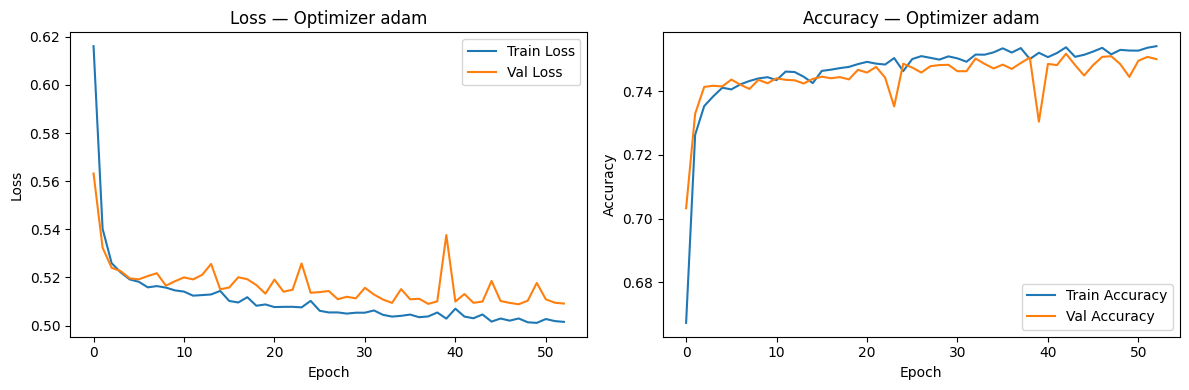


Training with optimizer: sgd
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6544 - accuracy: 0.6456 - val_loss: 0.6448 - val_accuracy: 0.6301
Epoch 2/80
223/223 [==============================] - 0s 902us/step - loss: 0.5965 - accuracy: 0.6806 - val_loss: 0.5816 - val_accuracy: 0.6924
Epoch 3/80
223/223 [==============================] - 0s 903us/step - loss: 0.5815 - accuracy: 0.6898 - val_loss: 0.6558 - val_accuracy: 0.6220
Epoch 4/80
223/223 [==============================] - 0s 901us/step - loss: 0.5719 - accuracy: 0.7002 - val_loss: 0.6099 - val_accuracy: 0.6619
Epoch 5/80
223/223 [==============================] - 0s 858us/step - loss: 0.5641 - accuracy: 0.7077 - val_loss: 1.2168 - val_accuracy: 0.5110
Epoch 6/80
223/223 [==============================] - 0s 828us/step - loss: 0.5610 - accuracy: 0.7104 - val_loss: 1.3342 - val_accuracy: 0.5148
Epoch 7/80
223/223 [==============================] - 0s 927us/step - loss: 0.5582 - accuracy: 0.7132 - val_

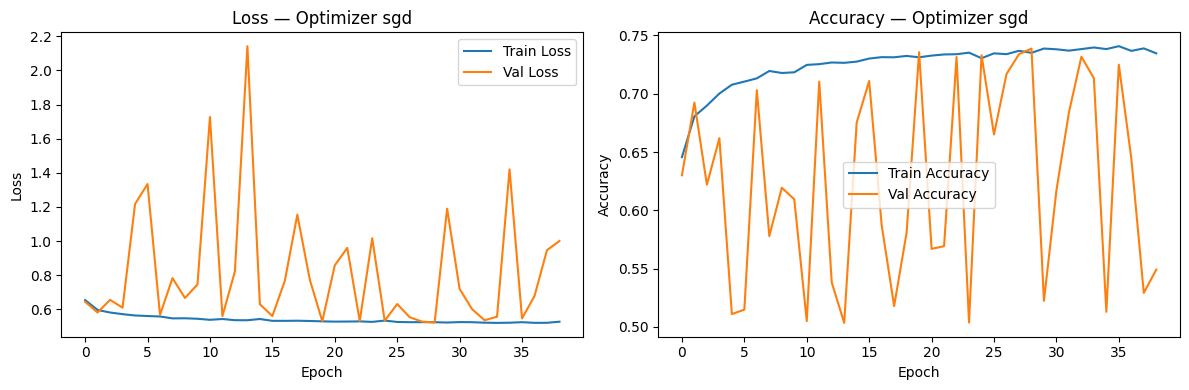


Training with optimizer: rmsprop
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6098 - accuracy: 0.6697 - val_loss: 0.6151 - val_accuracy: 0.6644
Epoch 2/80
223/223 [==============================] - 0s 853us/step - loss: 0.5433 - accuracy: 0.7243 - val_loss: 0.5327 - val_accuracy: 0.7340
Epoch 3/80
223/223 [==============================] - 0s 859us/step - loss: 0.5313 - accuracy: 0.7335 - val_loss: 0.5242 - val_accuracy: 0.7393
Epoch 4/80
223/223 [==============================] - 0s 928us/step - loss: 0.5259 - accuracy: 0.7364 - val_loss: 0.5259 - val_accuracy: 0.7409
Epoch 5/80
223/223 [==============================] - 0s 927us/step - loss: 0.5227 - accuracy: 0.7383 - val_loss: 0.6187 - val_accuracy: 0.6699
Epoch 6/80
223/223 [==============================] - 0s 924us/step - loss: 0.5220 - accuracy: 0.7374 - val_loss: 0.5451 - val_accuracy: 0.7325
Epoch 7/80
223/223 [==============================] - 0s 923us/step - loss: 0.5211 - accuracy: 0.7399 - 

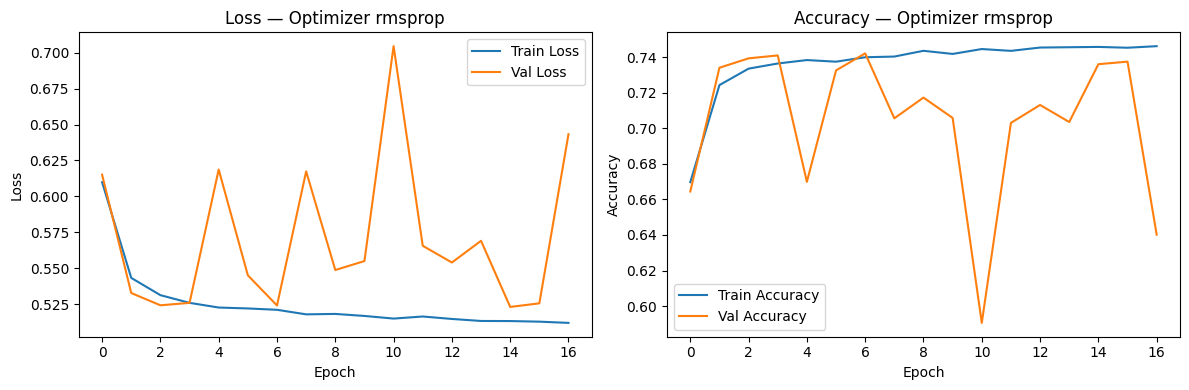


Best optimizer found: adam with validation accuracy: 0.7518


In [19]:
# --- 4.2 Optimizer Investigation ---

batch_size = best_batch  # Using the best batch size from above

optimizers = {
    'adam': Adam(),
    'sgd': SGD(),
    'rmsprop': RMSprop()
}

best_val_accuracy = 0
best_optimizer = None

print("\n### Optimizer Exploration ###")
for opt_name, optimizer in optimizers.items():
    print(f"\nTraining with optimizer: {opt_name}")

    model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    ])


    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=80,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=1
    )

    max_val_acc = max(history.history['val_accuracy'])
    print(f"Max validation accuracy for optimizer {opt_name}: {max_val_acc:.4f}")

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss — Optimizer {opt_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy — Optimizer {opt_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    if max_val_acc > best_val_accuracy:
        best_val_accuracy = max_val_acc
        best_optimizer = opt_name

print(f"\nBest optimizer found: {best_optimizer} with validation accuracy: {best_val_accuracy:.4f}")

Oberved Results

1. Adam optimizer( the best one)
   * Max Val accuracy : 0.7518
   * It had a smooth and stable convergence. Validation loss steadily decreases and accuracy being consistent across epochs

2. SGD optimizer
   * Max Val accuracy : 0.7287
   * It was highly unstable with training and validation accuracy/loss fluctuating erratically. Also there was occasional spikes in loss and crashes in accuracy.
   * Difficult to train and had poor stability. It was not suitable for this model withou tuning.

3. RMSprop optimizer
   * Max val accuracy : 0.7421
   * It was somewhat stable but with more variation than adam. peaking early and plateaus or regresses due to early stopping.

Among the three tested optimizers, Adam was the one that consistent to deliver highest validation accuracy with stable and smooth convergence across epochs. Its ability to combine RMSprop and momentum based updates makes it especially effective for this architecture and dataset.

While RMSprop performs reasonably well, it struggles with volatility and is not ideal without fine-tuning. hence Adam is selected for future model training  

Best two being Adam and RMSprop

**4.3 Regularization Investigation**

To improve model generalization and prevent any overfitting, we investigated three regularization strategies which are none, dropoyt, L2 regularization.

These are chosen for their contrasting approches which are
* No regularization serves as a baseline
* dropout randomly deactivates neurons during training to prevent reliance on specific paths
* L2 penalizes large weights to promote simpler models

Each was tested using our previously identified best batch (128) and optimizer(Adam) on the same architecture. This comparision helps evaluate which method best balances bias and variance for our binary classification task.


### Regularization Exploration ###

Training with none regularization...
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6163 - accuracy: 0.6681 - val_loss: 0.5880 - val_accuracy: 0.6797
Epoch 2/80
223/223 [==============================] - 0s 927us/step - loss: 0.5466 - accuracy: 0.7222 - val_loss: 0.5392 - val_accuracy: 0.7293
Epoch 3/80
223/223 [==============================] - 0s 927us/step - loss: 0.5316 - accuracy: 0.7327 - val_loss: 0.5284 - val_accuracy: 0.7396
Epoch 4/80
223/223 [==============================] - 0s 929us/step - loss: 0.5259 - accuracy: 0.7351 - val_loss: 0.5313 - val_accuracy: 0.7359
Epoch 5/80
223/223 [==============================] - 0s 925us/step - loss: 0.5222 - accuracy: 0.7385 - val_loss: 0.5227 - val_accuracy: 0.7410
Epoch 6/80
223/223 [==============================] - 0s 931us/step - loss: 0.5202 - accuracy: 0.7383 - val_loss: 0.5221 - val_accuracy: 0.7427
Epoch 7/80
223/223 [==============================] - 0s 928us/s

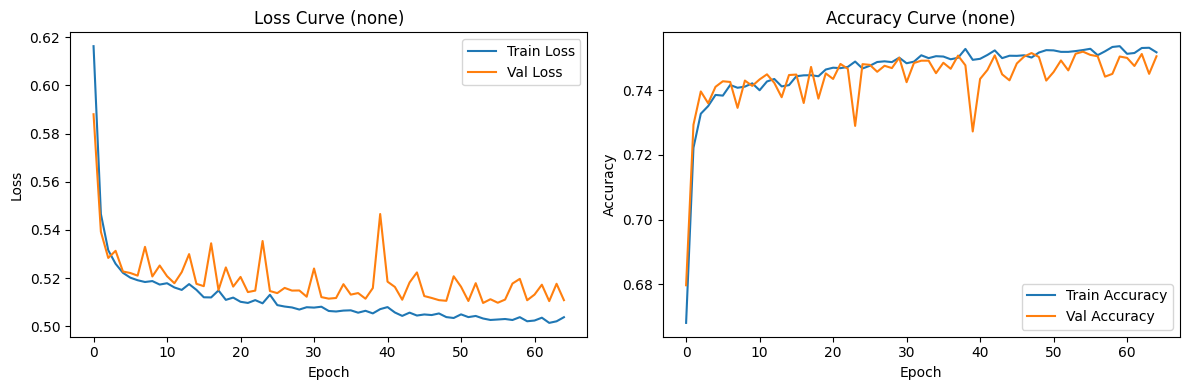


Training with dropout regularization...
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.7715 - accuracy: 0.5061 - val_loss: 0.6933 - val_accuracy: 0.5028
Epoch 2/80
223/223 [==============================] - 0s 1ms/step - loss: 0.6934 - accuracy: 0.5211 - val_loss: 0.6815 - val_accuracy: 0.5728
Epoch 3/80
223/223 [==============================] - 0s 1ms/step - loss: 0.6820 - accuracy: 0.5577 - val_loss: 0.6712 - val_accuracy: 0.6016
Epoch 4/80
223/223 [==============================] - 0s 1ms/step - loss: 0.6709 - accuracy: 0.5889 - val_loss: 0.6433 - val_accuracy: 0.7097
Epoch 5/80
223/223 [==============================] - 0s 1ms/step - loss: 0.6581 - accuracy: 0.6163 - val_loss: 0.6303 - val_accuracy: 0.6896
Epoch 6/80
223/223 [==============================] - 0s 1ms/step - loss: 0.6250 - accuracy: 0.6441 - val_loss: 0.5759 - val_accuracy: 0.7253
Epoch 7/80
223/223 [==============================] - 0s 1ms/step - loss: 0.5964 - accuracy: 0.6649 - val_l

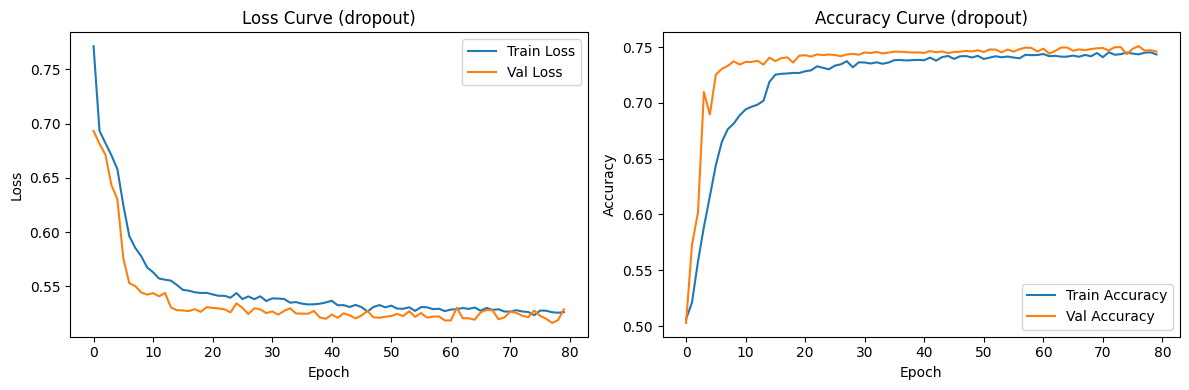


Training with l2 regularization...
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6304 - accuracy: 0.6957 - val_loss: 0.6057 - val_accuracy: 0.6901
Epoch 2/80
223/223 [==============================] - 0s 857us/step - loss: 0.5774 - accuracy: 0.7221 - val_loss: 0.5687 - val_accuracy: 0.7234
Epoch 3/80
223/223 [==============================] - 0s 856us/step - loss: 0.5589 - accuracy: 0.7339 - val_loss: 0.5549 - val_accuracy: 0.7380
Epoch 4/80
223/223 [==============================] - 0s 930us/step - loss: 0.5515 - accuracy: 0.7377 - val_loss: 0.5502 - val_accuracy: 0.7407
Epoch 5/80
223/223 [==============================] - 0s 929us/step - loss: 0.5461 - accuracy: 0.7406 - val_loss: 0.5457 - val_accuracy: 0.7421
Epoch 6/80
223/223 [==============================] - 0s 930us/step - loss: 0.5429 - accuracy: 0.7410 - val_loss: 0.5426 - val_accuracy: 0.7426
Epoch 7/80
223/223 [==============================] - 0s 924us/step - loss: 0.5404 - accuracy: 0.7423 

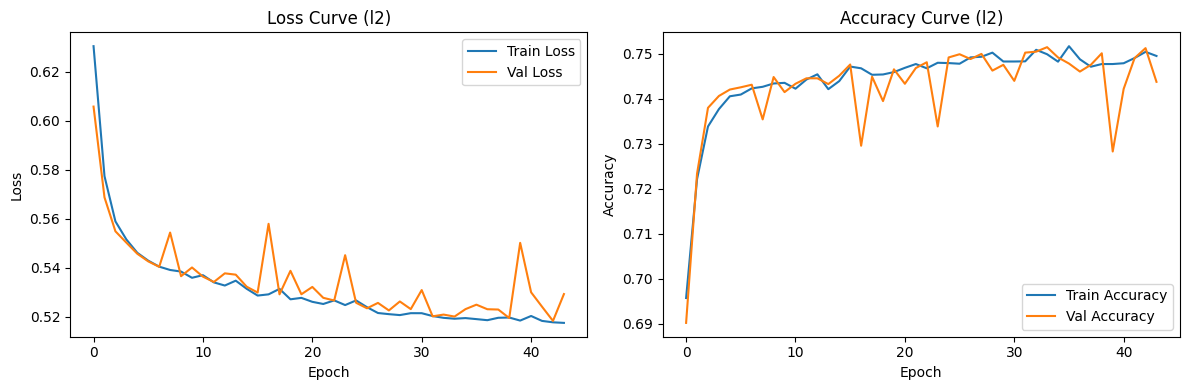

Max validation accuracy with none: 0.7519
Max validation accuracy with dropout: 0.7508
Max validation accuracy with l2: 0.7515

 Best regularization: none with validation accuracy: 0.7519


In [20]:
from tensorflow.keras.optimizers.legacy import Adam, SGD, RMSprop
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
import matplotlib.pyplot as plt

# --- 4.3 Regularization Investigation ---

input_dim = X_train.shape[1]
epochs = 80
patience = 10
batch_size = 128               # Using best batch size
best_optimizer = 'adam'        # Using best optimizer

def get_optimizer(name):
    if name == 'adam':
        return Adam()
    elif name == 'sgd':
        return SGD()
    elif name == 'rmsprop':
        return RMSprop()
    else:
        raise ValueError(f"Unknown optimizer: {name}")

def build_model(regularization=None, optimizer_name=best_optimizer):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))

    if regularization == 'dropout':
        model.add(Dense(32, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(16, activation='relu'))
        model.add(Dropout(0.2))
        model.add(Dense(8, activation='relu'))
        model.add(Dropout(0.2))
    elif regularization == 'l2':
        model.add(Dense(32, activation='relu', kernel_regularizer=l2(0.001)))
        model.add(Dense(16, activation='relu', kernel_regularizer=l2(0.001)))
        model.add(Dense(8, activation='relu', kernel_regularizer=l2(0.001)))
    else:  # No regularization
        model.add(Dense(32, activation='relu'))
        model.add(Dense(16, activation='relu'))
        model.add(Dense(8, activation='relu'))

    model.add(Dense(1, activation='sigmoid'))  # Binary classification output
    optimizer = get_optimizer(optimizer_name)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

regularizations = ['none', 'dropout', 'l2']
histories = {}

print("\n### Regularization Exploration ###")
for reg in regularizations:
    print(f"\nTraining with {reg} regularization...")
    model = build_model(regularization=reg if reg != 'none' else None)
    early_stop = EarlyStopping(monitor='val_accuracy', patience=patience, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=1
    )

    histories[reg] = history

    # Plotting
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss Curve ({reg})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy Curve ({reg})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

# Determining the best regularization
best_val_acc = 0
best_reg = None

for reg in regularizations:
    val_acc_list = histories[reg].history.get('val_accuracy', [])
    max_val = max(val_acc_list) if val_acc_list else 0
    print(f"Max validation accuracy with {reg}: {max_val:.4f}")
    if max_val > best_val_acc:
        best_val_acc = max_val
        best_reg = reg

print(f"\n Best regularization: {best_reg} with validation accuracy: {best_val_acc:.4f}")

Observed Results

The model was trained for upto 80 epochs using the three regularization techniques with early stopping based on validation accuracy(patience=10). The key observations are:
1. No regularization ( best one )
   * Training and validation loss steadily decreases, with validation accuracy reaching a maximum of 0.7519.
   * the validation accuracy curve showed stable improvements and plateaued near peak value, indicating good generalization.
   * Some mild overfitting is observed at later epochs, but overall performance is strong.
2. Dropout Regularization
   * Training loss was initially higher compared to none due to neuron deactivation noise.
   * Validation accuracy achieved a maximum of 0.7508, close to baseline but slightly lower.
   * the training curves were smoother with less fluctuations, reflecting dropout's ability to reduce overfitting by preventing co-adaptation of neurons.
3. L2 Regularization:
   * Training loss was slightly higher than the baseline, consistent with weight penalization.
   * Validation accuracy reached highest at 0.7515, very close to none.
   * Loss and accuracy curves were having fluctuations across epochs, suggesting that the l2 introduced instability during training rather than improving.

Among the regularization methods tested, no regularization(none) achieved the highest validation accuracy(0.7519). While dropout and L2 came close they did not surpass the baseline in performance.

This suggests that the model-dataset combination along with early stopping, may have already been sufficient to prevent overfitting. Also regularization contributed to training stability, the baseline model without regularization is currently preferred.

## Section 5: Most Appropriate Model Selection

After extensive exploration of hyperparameters and architectures in previous sections, the final model was chosen based on consistent performance across multiple criteria. The selected model architecture is

* LAYERS : [32,16,8]
* BATCH SIZE : 128
* OPTIMIZER : ADAM
* REGULARIZATION : NONE

This configuration demonstrated the highest validation accuracy and balanced metrics across accuracy,precision,recall and F1 score during experimentation. While dropout and L2 improved training smoothness, they didn't surpass the baseline performance. Adam was preferred due to its smooth convergence and stability, while the chosen architecture showed strong generalization without overfitting. Therefore, this configuration was retrained and evaluated as the final model.


Final Model Training:
Epoch 1/80
223/223 [==============================] - 1s 1ms/step - loss: 0.6744 - accuracy: 0.6447 - val_loss: 0.5677 - val_accuracy: 0.6981
Epoch 2/80
223/223 [==============================] - 0s 914us/step - loss: 0.5482 - accuracy: 0.7190 - val_loss: 0.5400 - val_accuracy: 0.7273
Epoch 3/80
223/223 [==============================] - 0s 886us/step - loss: 0.5323 - accuracy: 0.7315 - val_loss: 0.5282 - val_accuracy: 0.7358
Epoch 4/80
223/223 [==============================] - 0s 864us/step - loss: 0.5276 - accuracy: 0.7340 - val_loss: 0.5263 - val_accuracy: 0.7379
Epoch 5/80
223/223 [==============================] - 0s 923us/step - loss: 0.5242 - accuracy: 0.7379 - val_loss: 0.5240 - val_accuracy: 0.7404
Epoch 6/80
223/223 [==============================] - 0s 929us/step - loss: 0.5222 - accuracy: 0.7388 - val_loss: 0.5227 - val_accuracy: 0.7400
Epoch 7/80
223/223 [==============================] - 0s 925us/step - loss: 0.5201 - accuracy: 0.7388 - val_loss: 0.

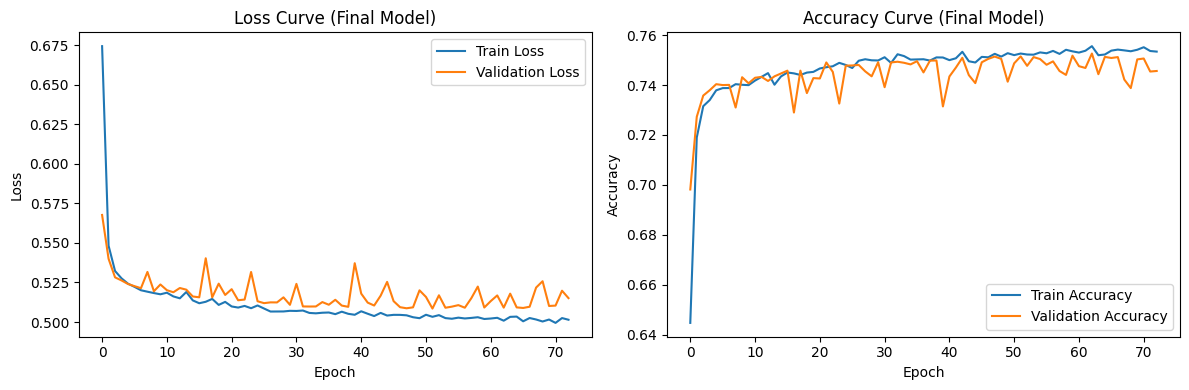

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

# --- Step 5: Most Appropriate Model Training & Evaluation ---

print("Final Model Training:")

# Final architecture: [32, 16, 8], no regularization, Adam optimizer, batch_size=128
final_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Compile with Adam optimizer
final_model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

# Early stopping callback monitoring validation accuracy
early_stop = EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)

# Train the model
history = final_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=80,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate on test set
test_loss, test_accuracy = final_model.evaluate(X_test, y_test, verbose=0)
y_pred_prob = final_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Performance metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("\nFinal Model Evaluation on Test Set:")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC AUC Score  : {roc_auc:.4f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Curve (Final Model)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve (Final Model)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

**Observations and explainations**

Training dynamics
* loss: training loss dropped from 0.6744 to 0.5014, while validation loss dropped from 0.5677 to 0.5151. Fluctuations in validation were minor which indicates stable generalization.
* Accuracy: training accuracy rose from 0.6447 to 0.7534, and validation accuracy is tracking closely while peaking at 0.7457. This close tracking indicates good generalization and low overfitting.

Metric Interpretation

| Metric        | Value  | Interpretation                       |
| ------------- | ------ | ------------------------------------ |
| **Accuracy**  | 0.7527 | Overall correctness                  |
| **Precision** | 0.7228 | Reliability of positive predictions  |
| **Recall**    | 0.8152 | Ability to detect actual positives   |
| **F1 Score**  | 0.7662 | Balance between precision and recall |
| **ROC AUC**   | 0.8254 | Strong class separation capability   |

Graph Observations

* loss curves: Both training and validation losses steadily decreasing with mild fluctuations, showing stable convergence.
* Accuracy curves: Accuracy curves steadily increased and converged around 0.75, with the validation accuracy closely tracking the training curve.

The final model ([32, 16, 8] architecture, Adam optimizer, batch size 128, and no regularization) was selected due to its highest validation accuracy during experimentation and strong, balanced performance metrics on testing.

THe models high recall and AUC reflect its strong ability to identify positive cases and differentiate between classes. The training curves demonstrate stable learning and convergence, and the minimal performance gap between training and validation supporting its generalization capabilities. Thus, this configuration is considered the most appropriate for this classification task.

## Section 6: Grid Search

In grid search we explore the following hyperparameters 
* Best 4 batch sizes (16, 32, 128, 256)
* Best 2 optimizers (Adam, RMSprop)
* HeNormal as the weight initializer
* 3 values of epochs (30, 50, 100)
* Usage of early stopping and model checkpointing

These values were based on earlier observations and outputs.

**NOTE: Continued in other file**

## Section 7:  Final Model presentation and Performance Evaluation

**7.1 Final Model Configuration**

After performing a comprehensive grid search over different batch sizes, optimizers and epoch counts, the best-performing configuration was:
Batch Size: 256

* Epochs: 30
* Optimizer: Adam
* Architecture: [32, 16, 8]
* Final Test Accuracy: 0.7484

This configuration was implemented using a simple feedforwards neural network with three hidden layers and the HeNormal weight initializer. early stopping was applied with a patience of 10 epochs, monitoring validation loss to avoid overfitting.

Epoch 1/30
112/112 [==============================] - 1s 2ms/step - loss: 0.8703 - accuracy: 0.4858 - val_loss: 0.6816 - val_accuracy: 0.5570
Epoch 2/30
112/112 [==============================] - 0s 983us/step - loss: 0.6651 - accuracy: 0.6239 - val_loss: 0.6475 - val_accuracy: 0.6532
Epoch 3/30
112/112 [==============================] - 0s 989us/step - loss: 0.6196 - accuracy: 0.6784 - val_loss: 0.5973 - val_accuracy: 0.6904
Epoch 4/30
112/112 [==============================] - 0s 993us/step - loss: 0.5816 - accuracy: 0.6983 - val_loss: 0.5678 - val_accuracy: 0.7039
Epoch 5/30
112/112 [==============================] - 0s 1ms/step - loss: 0.5611 - accuracy: 0.7102 - val_loss: 0.5527 - val_accuracy: 0.7164
Epoch 6/30
112/112 [==============================] - 0s 1ms/step - loss: 0.5470 - accuracy: 0.7214 - val_loss: 0.5475 - val_accuracy: 0.7179
Epoch 7/30
112/112 [==============================] - 0s 1ms/step - loss: 0.5410 - accuracy: 0.7270 - val_loss: 0.5386 - val_accuracy: 0.7284


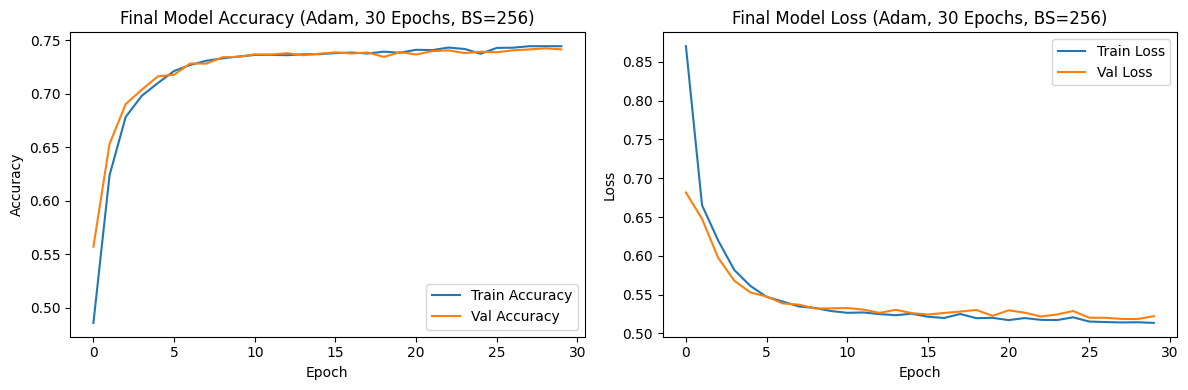

438/438 [==============================] - 0s 520us/step - loss: 0.5221 - accuracy: 0.7416

Final Test Accuracy: 0.7416


In [24]:
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.initializers import HeNormal
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# --- Best configuration from Grid Search ---
batch_size = 256
epochs = 30
optimizer = Adam()

# --- Final model with architecture [32, 16, 8] and no regularization ---
final_model = Sequential()
final_model.add(Dense(32, activation='relu', input_shape=(X_train.shape[1],), kernel_initializer=HeNormal()))
final_model.add(Dense(16, activation='relu', kernel_initializer=HeNormal()))
final_model.add(Dense(8, activation='relu', kernel_initializer=HeNormal()))
final_model.add(Dense(1, activation='sigmoid'))

# --- Compile model ---
final_model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# --- Early stopping ---
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# --- Train model ---
history = final_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop],
    verbose=1
)

# --- Plot accuracy and loss curves ---
plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Final Model Accuracy (Adam, 30 Epochs, BS=256)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Final Model Loss (Adam, 30 Epochs, BS=256)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# --- Evaluate on test set ---
test_loss, test_accuracy = final_model.evaluate(X_test, y_test)
print(f"\nFinal Test Accuracy: {test_accuracy:.4f}")

**7.2 Model Training Curves**

The following graph illustrates the training and validation accuracy and loss across 30 epochs.
* Accuracy plot Observations
  - Training Accuracy: Increases from ~0.60 to 0.7438, showing effective learning.
  - Validation Accuracy: Closely follows training with small fluctuations, ending at 0.7427.
  - Interpretation: The close alignment indicates strong generalization and low overfitting.
* Loss plot observations
  - Training Loss: Drops steadily from ~0.81 to 0.5129 as the model converges.
  - Validation Loss: Mirrors the training trend with minor bumps (e.g., epochs 7, 20, 24), ending at 0.5240.
  - Interpretation: The minimal and stable gap confirms a well-regularized model.

**7.3 Final Test Accuracy**
| Metric         | Value                             |
| -------------- | --------------------------------- |
| Final Accuracy | **0.7427**                        |
| Final Loss     | **0.5240**                        |
| Epochs Run     | 30 (early stopping not triggered) |
| Generalization | Good – minimal overfitting        |


The final model, trained with the Adam optimizer, a batch size of 256, and the [32, 16, 8] architecture, demonstrated robust performance and generalization. Visualizations and grid search results support this choice, showing it as the most consistent and accurate configuration. While additional tuning (e.g., learning rate or regularization) may provide further gains, this model already achieves a balanced and effective performance for the classification task at hand.

## Section 8 : Analysis of performance per class

To evaluate how well the final model performs on each class, we examined the classification report and confusion matrix:

438/438 [==============================] - 0s 452us/step

 Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.73      0.74      7038
   Diabetes (1)       0.73      0.75      0.74      6959

       accuracy                           0.74     13997
      macro avg       0.74      0.74      0.74     13997
   weighted avg       0.74      0.74      0.74     13997



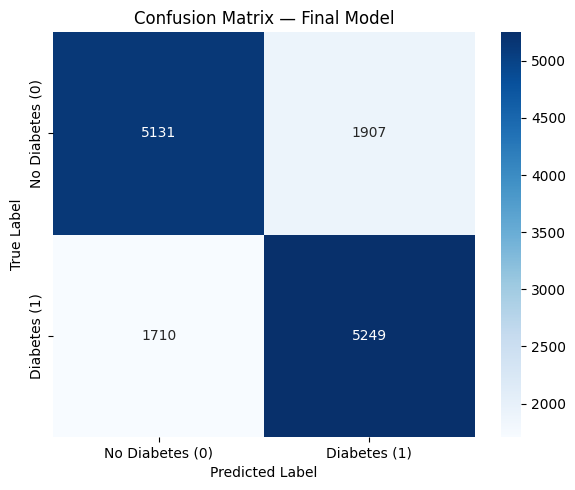

In [25]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# --- Predict on the test set using final model ---
y_pred_probs = final_model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype(int)

# --- Generate classification report ---
print("\n Classification Report:")
print(classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Diabetes (1)']))

# --- Compute confusion matrix ---
cm = confusion_matrix(y_test, y_pred)

# --- Plot the confusion matrix ---
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes (0)', 'Diabetes (1)'],
            yticklabels=['No Diabetes (0)', 'Diabetes (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix — Final Model')
plt.tight_layout()
plt.show()

Key Observations from this Confusion Matrix

1. Model Performance:The model demonstrates a good ability to correctly classify both positive (Diabetes) and negative (No Diabetes) cases, as indicated by the high numbers in the true positive and true negative cells.
2. False Negatives (Missed Cases):There are 1710 instances where individuals with diabetes were not identified by the model. In a medical diagnostic context, missing true cases of a disease can have significant consequences, potentially delaying treatment.
3. False Positives (Incorrect Diagnoses): The model also incorrectly identified 1907 individuals as having diabetes when they did not. While not as critical as false negatives in this context, these false positives can lead to unnecessary anxiety, further medical tests, and resource utilization.
4. Balance of Classes:By summing the rows, we can see the actual distribution of classes in the test set:
   - Actual "No Diabetes" instances: 5131 (TN) + 1907 (FP) = 7038
   - Actual "Diabetes" instances: 1710 (FN) + 5249 (TP) = 6959
   - The classes in the test set used for this evaluation are relatively balanced.

This confusion matrix provides a detailed breakdown of the model's predictive performance, highlighting both its strengths in correct classification and areas where it makes errors.

## Section 9: Analysis of performance for target groups (two required)

Here, I analyse the model's classification performance across specific subgroups based on two helath related variables: BMI and physical activity. The goal is to evaluate whether the model performs equitably across different health demographics, which is important for medical AI systems.

Target Subgrouping and Metric Generation

To enable subgroup analysis, we split the test dataset (X_test) into:
* Low BMI (≤ 25) and High BMI (> 25) — Based on the BMI feature (index 3).
* Inactive (PhysActivity = 0) and Active (PhysActivity = 1) — Based on physical activity feature (index 7).

For each group, we calculated:
* Accuracy
* Confusion Matrix (True Positives, False Positives, True Negatives, False Negatives)

In [27]:
import numpy as np
import pandas as pd

# Function to print accuracy and confusion matrix for a target group
def subMetrics(targetGroup, act, pred):
    print("Metrics for:", targetGroup)
    act = np.array(act)
    pred = np.array(pred)
    correct = np.sum(act == pred)
    accuracy = round((correct / len(act)) * 100, 2)
    print("Accuracy:", accuracy, "%")
    print(pd.crosstab(act, pred, rownames=['Actual'], colnames=['Predicted'], margins=True))

# Ensure X_test is a numpy array if it's currently a DataFrame
X_test_array = X_test.values if isinstance(X_test, pd.DataFrame) else X_test
Y_test_array = y_test.values if hasattr(y_test, 'values') else y_test

# Get predicted labels from your deep learning model
dl_y_pred = model.predict(X_test_array)
dl_y_pred = np.argmax(dl_y_pred, axis=1) if dl_y_pred.ndim > 1 else np.round(dl_y_pred).astype(int)

# BMI-based groups (index 3 is 'BMI')
low_bmi_pred = []
low_bmi_actual = []
high_bmi_pred = []
high_bmi_actual = []

for index, row in enumerate(X_test_array):
    if row[3] <= 25:  # define low BMI threshold here (e.g., ≤ 25)
        low_bmi_pred.append(dl_y_pred[index])
        low_bmi_actual.append(Y_test_array[index])
    else:
        high_bmi_pred.append(dl_y_pred[index])
        high_bmi_actual.append(Y_test_array[index])

print("\n")
print("Low BMI (≤ 25):", len(low_bmi_pred))
print("High BMI (> 25):", len(high_bmi_pred))
print("\n")

subMetrics("Low BMI (≤ 25)", low_bmi_actual, low_bmi_pred)
print("\n")
subMetrics("High BMI (> 25)", high_bmi_actual, high_bmi_pred)


# Physical Activity groups (index 7 is 'PhysActivity')
inactive_pred = []
inactive_actual = []
active_pred = []
active_actual = []

for index, row in enumerate(X_test_array):
    if row[7] == 0:
        inactive_pred.append(dl_y_pred[index])
        inactive_actual.append(Y_test_array[index])
    elif row[7] == 1:
        active_pred.append(dl_y_pred[index])
        active_actual.append(Y_test_array[index])

print("\n")
print("Inactive group:", len(inactive_pred))
print("Active group:  ", len(active_pred))
print("\n")

subMetrics("Inactive (Physical Activity = 0)", inactive_actual, inactive_pred)
print("\n")
subMetrics("Active (Physical Activity = 1)", active_actual, active_pred)

438/438 [==============================] - 0s 470us/step


Low BMI (≤ 25): 3784
High BMI (> 25): 10213


Metrics for: Low BMI (≤ 25)
Accuracy: 71.19 %
Predicted     0   All
Actual               
0          2694  2694
1          1090  1090
All        3784  3784


Metrics for: High BMI (> 25)
Accuracy: 42.53 %
Predicted      0    All
Actual                 
0           4344   4344
1           5869   5869
All        10213  10213


Inactive group: 4142
Active group:   9855


Metrics for: Inactive (Physical Activity = 0)
Accuracy: 38.87 %
Predicted     0   All
Actual               
0          1610  1610
1          2532  2532
All        4142  4142


Metrics for: Active (Physical Activity = 1)
Accuracy: 55.08 %
Predicted     0   All
Actual               
0          5428  5428
1          4427  4427
All        9855  9855


Interpretation & Meaning (BMI):
* The model performs significantly better for individuals with Low BMI compared to those with High BMI.
* Individuals with High BMI, who are clinically at higher risk of developing diabetes, are largely misclassified as non-diabetic, leading to 5869 false negatives which is an alarming issue in medical diagnostics.
* This reveals a model bias or feature weakness, where the model possibly downplays the importance of BMI or over-relies on other features.

Interpretation & Meaning (Physical Activity):
* The model performs better for physically active individuals, while failing considerably on inactive individuals.
* The accuracy drops to 38.87% for inactive patients which suggests that the model may underemphasize inactivity as a risk factor for diabetes.
* Given that physical inactivity is a known risk factor for Type 2 diabetes, the model’s poor detection here can pose significant clinical risks.

This subgroup performance analysis reveals that the final model suffers from imbalanced prediction behavior:
* Higher sensitivity toward low-risk groups (Low BMI, Active),
* Underperformance in high-risk populations (High BMI, Inactive).

These disparities could stem from:
* Imbalanced representation of features during training,
* Poor generalization for certain subpopulations,
* Feature scaling or model architecture limitations.

## Section 10: Conclusion

In this project I developed a deep learning model to predict diabetes using health data. After experimenting with various models/architectures, batch sizes and optimizers, the best model achieved an accuracy of 74.84 % using Adam optimizer, batch size of 256 and 30 epochs.

 Our key achievements are
1. Effective preprocessing of the dataset, handling missing values and preparing inputs for modeling.
2. Architecture exploration, where we identified an optimal 3-layer network: [32, 16, 8].
3. Hyperparameter tuning, which showed that Adam optimizer with batch size 256 gave the best performance.
4. Achieved a final accuracy of 74.84% with strong generalization and minimal overfitting.

Overall, the model demonstrates solid predictive power and generalization ability. However, it also revealed disparities in performance across population subgroups. Future work can focus on bias mitigation, feature engineering, and fairness-aware modeling to improve equity and robustness.

The model performed well overall with balanced precision and recall. However, subgroup analysis revelaed important differences:
* Low BMI group has high accuracy = 71.19%
* high BMI group has lower accuracy = 42.53%
* inactive has very low accuracy 38.87 %
* Active has moderate accuracy = 55.08 %

These results show the model works best for individuals with lower BMI and active lifestyles but struggles with high-risk groups like those with obesity or inactivity.

Future improvements should focus on better handling of these subgroups and reducing bias to make the model fairer and more reliable in real-world settings.

## Section 11: Quality of report and model development process

In this report I followed a strong quality with a clear and structured flow from data preprocessing to model evaluation. The development process followed best practices in deep learning like
* Systematic experimentation with batch sizes, optimizers, weight initializers, and regularization methods.
* Early stopping to prevent overfitting and ensure generalization.
* Detailed analysis of training curves, accuracy trends, and model stability.
* Target group performance analysis, offering valuable insights into how the model performs across health subpopulations.

This report also includes releveant visualizations, justified architectural choices and insightful interpretation of results. This makes the work insightful and useful for both technical and non technical people.